# FP / FN als Signal für Latent-TTA — Erkenntnisse (PMRI)

Dieses Notebook fasst alles zusammen, was wir bisher über **False Positives (FP)** und **False
Negatives (FN)** der U-Net-Maske als Signal für die Test-Time-Adaptation wissen: Orakel (echte
Zahlen aus den Labels), gelernte FP/FN-Heads, TTA mit diesen Heads und das Pseudo-Label-Orakel.
Alle Zahlen und Abbildungen werden unten aus `results/` und `logs/` berechnet, nichts ist
fest eingetragen.

**Standard-Setup, falls nicht anders angegeben:** Test-Domäne, echter harter Dice, 100 TTA-Schritte,
affine Anpassung der latenten Features an den Stellen [0, 17] (nach der Normierung), Mittel über die
5 Paare Score-Predictor `cleanHalf_k` ↔ Head `fpfn_k`.

> Läufe **ohne μ̂ im Objective und ohne Head** (nur echte FP/FN, Pseudo-Label-Orakel) sind für alle 5
> Paare identisch, weil alle dieselbe eingefrorene U-Net nutzen; dort ist es effektiv ein Lauf.

## Kurzfassung

1. **Echte FP/FN, in jedem Schritt neu berechnet, sind ein sehr starkes Signal** (Abb. 1, 2):
   3T→1.5T 0.677 → 0.886, ohne μ̂ und ohne Gewichtung. μ̂ bringt dann nichts mehr dazu.
2. **Die Wirkung kommt von der Richtung, nicht von der Zahl** (Abb. 2): Ein Größen-Orakel, das FP/FN
   nur einmal kennt, bringt viel weniger, und Rauschen auf der Zahl stört kaum. Der Gradient
   von FP/FN ist die Label-Karte — er sagt, *wo* die Maske sich ändern muss.
3. **Nur die gemeinsame Form log(1+FP+FN) funktioniert** (Abb. 3). Die getrennte Form
   log(1+FP)+log(1+FN) entfernt FP und lässt FN wachsen.
4. **Die Restlücke zum Dice-Orakel sind die verpassten Prostatas** (Abb. 4, 5): Wo die U-Net die
   Prostata gar nicht findet, hilft FP/FN kaum; das lokale Minimum ist dort die leere Maske.
5. **Die FP/FN-Heads generalisieren nicht, nicht einmal in der eigenen Domäne** (Abb. 6, 7):
   gut auf den U-Net-Trainingsbildern, r ≈ 0 auf Validierung, FN unter Shift ×5 unterschätzt.
   Die Wahl des Checkpoints ist nicht schuld (Abb. 7b, 7c): Die Validierungskorrelation ist über das
   ganze Training niedrig und verrauscht; frühere Epochen wären nicht besser gewesen.
6. **TTA mit den Heads verschlechtert die Masken** (Abb. 8–10): Der Head meldet weniger Fehler,
   die echten FN steigen. Die Adaptation nutzt den Head aus.
7. **Getrennte FP- und FN-Adversaries trennen FP und FN nicht** (Abb. 11): Beide erhöhen vor allem FN.
   Auch zwei komplett getrennte Heads für FP und FN generalisieren nicht besser (Abb. 7).
8. **Mit einer Pseudo-Label-Karte ĝ statt Labels funktioniert der Orakel-Mechanismus weiter**
   (Abb. 12, 13): Der Gewinn sinkt gleichmäßig mit der Qualität von ĝ (50 % der Fehler korrigiert →
   0.765, mehr als μ̂ allein). **Aber die TTA landet immer unter ĝ selbst** — ein Head, der ein
   gutes ĝ liefert, wäre direkt als Segmentierung besser.

In [1]:
%matplotlib inline
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
import pickle, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
warnings.filterwarnings('ignore')

ROOT = Path.cwd().resolve()
while not ((ROOT / 'results').is_dir() and (ROOT / 'src').is_dir()):
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Notebook bitte innerhalb des isbi26-implementation-Repos ausführen')
    ROOT = ROOT.parent
RES, LOGS = ROOT / 'results', ROOT / 'logs'
SPLITS = {'threet-to-onepointfivet': '3T→1.5T', 'promise12': 'PROMISE12', 'onepointfivet-to-threet': '1.5T→3T'}
_CACHE = {}

def load_pkl(f):
    f = str(f)
    if f not in _CACHE:
        with open(f, 'rb') as fh:
            _CACHE[f] = pickle.load(fh)
    return _CACHE[f]

def tta_files(run, split):
    return sorted(RES.glob(f'{run}/pmri_{split}_*cleanHalf_*/latent_tta.pkl'))

def get_t(e, key, col=None):
    """per-image tensor (float) or None; col selects a step from a *_per_step tensor"""
    v = e.get(key)
    if v is None or not torch.is_tensor(v) or v.numel() == 0:
        return None
    v = v.float()
    return v[:, col] if col is not None else v

def tta_row(run, split, dom='test'):
    per_ckpt = []
    for f in tta_files(run, split):
        e = load_pkl(f)['evaluation'][f'{split}_{dom}']
        size_after = get_t(e, 'size_after')
        if size_after is None:
            size_after = get_t(e, 'hard_size_per_step', -1)
        fp_b = get_t(e, 'fp_before'); fp_a = get_t(e, 'fp_after'); fn_b = get_t(e, 'fn_before'); fn_a = get_t(e, 'fn_after')
        fpp = get_t(e, 'fp_pred_per_step'); fnp = get_t(e, 'fn_pred_per_step')
        nan = float('nan'); m = lambda t: float(t.mean()) if t is not None else nan
        per_ckpt.append({
            'before': m(e['dice_before'].float()), 'after': m(e['dice_after'].float()),
            'best step': m(e['best_dice'].float()),
            'worse %': 100 * m((e['dice_after'] < e['dice_before'] - 0.01).float()),
            'empty %': 100 * m((size_after == 0).float()) if size_after is not None else nan,
            'FP before': m(fp_b), 'FP after': m(fp_a), 'FN before': m(fn_b), 'FN after': m(fn_a),
            'FP_hat before': m(fpp[:, 0]) if fpp is not None else nan,
            'FP_hat after': m(fpp[:, -1]) if fpp is not None else nan,
            'FN_hat before': m(fnp[:, 0]) if fnp is not None else nan,
            'FN_hat after': m(fnp[:, -1]) if fnp is not None else nan,
        })
    if not per_ckpt:
        return None
    df = pd.DataFrame(per_ckpt)
    row = df.mean().to_dict()
    row['after ± (ckpts)'] = df['after'].std(ddof=0)
    row['n ckpts'] = len(per_ckpt)
    return row

def tta_table(runs, splits=SPLITS, dom='test', cols=None):
    rows = []
    for label, run in runs:
        for s in splits:
            r = tta_row(run, s, dom)
            if r is not None:
                rows.append({'run': label, 'split': SPLITS[s], **r})
    df = pd.DataFrame(rows).set_index(['split', 'run'])
    return df[cols] if cols else df

def head_files(split, tag):
    return sorted(RES.glob(f'fpfn_head/pmri_{split}_*-{tag}_[0-9]_*/eval_data.pkl'))

def head_table(entries):
    """entries: [(label, split, tag)] -> metrics per domain, mean over the 5 heads"""
    rows = []
    for label, split, tag in entries:
        evs = [load_pkl(f)['evaluation'] for f in head_files(split, tag)]
        for dom in ('train', 'val', 'test'):
            vals = []
            for ev in evs:
                e = ev[f'{split}_{dom}']; s = e['summary']
                p = torch.expm1(e['pred'].float().clamp_min(0)); t = torch.expm1(e['target'].float())
                vals.append({'r log FP': s['corr_log_fp'], 'r log FN': s['corr_log_fn'],
                             'MAE log FP': s['mae_log_fp'], 'MAE log FN': s['mae_log_fn'],
                             'FP_hat / FP': float(p[..., 0].mean() / t[..., 0].mean()),
                             'FN_hat / FN': float(p[..., 1].mean() / t[..., 1].mean()),
                             'r Dice (implied)': s['corr_dice'], 'U-Net Dice': float(e['dice'].float().mean())})
            rows.append({'split': SPLITS[split], 'head': label, 'domain': dom, 'n heads': len(evs),
                         **pd.DataFrame(vals).mean().to_dict()})
    return pd.DataFrame(rows).set_index(['split', 'head', 'domain'])

ADV_LINE = re.compile(r'\[epoch (\d+)\]\s+(FP|FN) adversary: factor ([\d.]+) grad norm \S+ '
                      r'true Dice drop ([+-][\d.]+) true dlog FP ([+-][\d.]+) FN ([+-][\d.]+)')

def split_adversary_table(tag='fpfnsplit', ranges=((40, 70), (70, 150), (150, 250), (250, 400))):
    recs = []
    for f in sorted(LOGS.glob(f'train_{tag}_head_[0-9].log')):
        for line in open(f, errors='ignore'):
            for m in ADV_LINE.finditer(line):
                recs.append({'epoch': int(m.group(1)), 'adversary': m.group(2), 'step factor': float(m.group(3)),
                             'true Dice drop': float(m.group(4)), 'rise log(1+FP)': float(m.group(5)),
                             'rise log(1+FN)': float(m.group(6))})
    df = pd.DataFrame(recs)
    df['epochs'] = pd.cut(df['epoch'], [r[0] for r in ranges] + [ranges[-1][1]], right=False,
                          labels=[f'{a}-{b - 1}' for a, b in ranges])
    return df.groupby(['epochs', 'adversary'], observed=True)[
        ['step factor', 'true Dice drop', 'rise log(1+FP)', 'rise log(1+FN)']].mean()

def per_step_means(run, split, dom='test', keys=('dice_per_step', 'fp_hard_per_step', 'fn_hard_per_step',
                                                  'fp_pred_per_step', 'fn_pred_per_step')):
    out = {}
    for k in keys:
        arr = [get_t(load_pkl(f)['evaluation'][f'{split}_{dom}'], k) for f in tta_files(run, split)]
        arr = [a for a in arr if a is not None]
        if arr:
            out[k] = torch.cat(arr).mean(0).numpy()
    return out

def emptied_table(runs, splits=SPLITS, dom='test'):
    rows = []
    for label, run in runs:
        for s in splits:
            fs = tta_files(run, s)
            if not fs:
                continue
            n = tot = 0; dice_b = []; gt = []; gt_all = []
            for f in fs:
                e = load_pkl(f)['evaluation'][f'{s}_{dom}']
                if 'size_after' not in e:
                    continue
                m = e['size_after'] == 0
                n += int(m.sum()); tot += m.numel()
                dice_b.append(e['dice_before'][m].float()); gt.append(e['size_gt'][m].float()); gt_all.append(e['size_gt'].float())
            if tot:
                db = torch.cat(dice_b); g = torch.cat(gt)
                rows.append({'split': SPLITS[s], 'run': label, 'emptied %': 100 * n / tot,
                             'their Dice before (mean)': float(db.mean()) if n else float('nan'),
                             'their GT size (median)': float(g.median()) if n else float('nan'),
                             'GT size all images (median)': float(torch.cat(gt_all).median())})
    return pd.DataFrame(rows).set_index(['split', 'run'])


# ---- Darstellung ---------------------------------------------------------------------------------
pd.set_option('display.max_columns', 40)
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6'
NEUTRAL = '#b5b3ad'
# Rollen wie in den Meeting-Notebooks: μ̂ blau, Orakel grün, Ausgang grau; neu: FP/FN-Heads orange
GREEN, RED, REF, START = '#1baf7a', '#e34948', '#52514e', '#898781'
C_MU, C_HEAD, C_ORACLE = BLUE, ORANGE, GREEN
SEQ = ['#104281', '#1c5cab', '#3987e5', '#86b6ef']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'text.color': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
                     'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'figure.titlesize': 12,
                     'figure.titleweight': 'bold'})
SPLIT_ORDER = list(SPLITS)
T15 = 'threet-to-onepointfivet'

def evals(run, split, dom='test'):
    return [load_pkl(f)['evaluation'][f'{split}_{dom}'] for f in tta_files(run, split)]

def after_per_ckpt(run, split, dom='test'):
    return [float(e['dice_after'].float().mean()) for e in evals(run, split, dom)]

def before_dice(split, run='latent_tta_prenorm'):
    return float(evals(run, split)[0]['dice_before'].float().mean())

def label_bars(ax, bars, fmt='{:.3f}', pad=0.004, horizontal=True):
    for b in bars:
        if horizontal:
            ax.text(b.get_width() + pad, b.get_y() + b.get_height() / 2, fmt.format(b.get_width()),
                    va='center', ha='left', fontsize=9, color=INK)
        else:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + pad, fmt.format(b.get_height()),
                    va='bottom', ha='center', fontsize=8, color=INK)

def start_line(ax, x, label='Dice nach TTA'):
    ax.axvline(x, color=START, ls='--', lw=1.2, zorder=1)
    ax.set_xlabel(f'{label}   (gestrichelt: ohne TTA = {x:.3f})')

# ---- Fehlerkarten --------------------------------------------------------------------------------
C_TP, C_FP, C_FN = np.array([0.11, 0.69, 0.48]), np.array([0.89, 0.29, 0.28]), np.array([0.16, 0.47, 0.84])
ERR_LEGEND = [mpatches.Patch(color=C_TP, label='richtig (TP)'), mpatches.Patch(color=C_FP, label='FP (zu viel)'),
              mpatches.Patch(color=C_FN, label='FN (fehlt)')]

def dice_np(p, g):
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else 2 * (p & g).sum() / s

def crop_box(masks, pad=28):
    m = np.zeros_like(masks[0], dtype=bool)
    for x in masks:
        m |= x.astype(bool)
    if not m.any():
        H, W = m.shape
        return slice(H // 4, 3 * H // 4), slice(W // 4, 3 * W // 4)
    ys, xs = np.where(m)
    H, W = m.shape
    cy, cx = (ys.min() + ys.max()) // 2, (xs.min() + xs.max()) // 2
    h = max(ys.max() - ys.min(), xs.max() - xs.min()) // 2 + pad
    h = max(h, 48)
    return slice(max(cy - h, 0), min(cy + h, H)), slice(max(cx - h, 0), min(cx + h, W))

def error_panel(ax, img, pred, gt, title, box=None, alpha=0.55):
    img = img.astype(np.float32)
    lo, hi = np.percentile(img, [1, 99])
    img = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)
    rgb = np.repeat(img[..., None], 3, -1)
    p, g = pred.astype(bool), gt.astype(bool)
    for m, c in ((p & g, C_TP), (p & ~g, C_FP), (~p & g, C_FN)):
        rgb[m] = (1 - alpha) * rgb[m] + alpha * c
    if box is not None:
        rgb = rgb[box]
    ax.imshow(rgb, interpolation='nearest')
    ax.set_title(f'{title}\nDice {dice_np(p, g):.2f}', fontsize=9, fontweight='normal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

def example(run, split, idx, key='pred_final', ckpt=0):
    fs = tta_files(run, split)
    if not fs:
        return None
    ex = load_pkl(fs[ckpt])['evaluation'][f'{split}_test'].get('examples', {})
    if 'index' not in ex or len(ex['index']) == 0:
        return None
    pos = (ex['index'] == idx).nonzero()
    if len(pos) == 0 or key not in ex:
        return None
    k = int(pos[0, 0])
    return {'image': ex['image'][k].float().numpy(), 'target': ex['target'][k].numpy().astype(bool),
            'before': ex['pred_before'][k].numpy().astype(bool), 'pred': ex[key][k].numpy().astype(bool)}

print('Repo:', ROOT)

Repo: /root/workspace/repos/isbi26-implementation


## Überblick

| Kürzel | Was ins TTA-Objective geht | Labels? | Ergebnisordner |
|---|---|---|---|
| μ̂ allein | Aufstieg auf μ̂ | nein | `latent_tta_prenorm` |
| Dice-Orakel | Aufstieg auf den echten weichen Dice | **ja** | `latent_tta_oracle` |
| Größen-Orakel (exp5) | μ̂ − (log(1+Σp) − log(1+Ĝ))², Ĝ aus echten FP/FN von Schritt 0 (± Rauschen) | **ja** | `latent_tta_mu_size_*` |
| μ̂ + FP/FN getrennt / gemeinsam (exp6) | μ̂ − log(1+FP) − log(1+FN) bzw. μ̂ − log(1+FP+FN), echte weiche Zahlen in jedem Schritt | **ja** | `latent_tta_mu_fpfn_*` |
| nur echte FP/FN (exp8) | log(1+FP+FN) allein, ohne μ̂ | **ja** | `latent_tta_fpfnonly_oracle` |
| μ̂ + Head (exp7) | μ̂ − log(1+FP̂+FN̂), FP̂/FN̂ von einem Head (hart / weich / weich+down) | nein | `latent_tta_mu_fpfnhead*` |
| nur Head (exp8) | log(1+FP̂+FN̂) allein (harter Head / Head mit getrennten Adversaries) | nein | `latent_tta_fpfnonly_head*` |
| Pseudo-Label (exp9) | log(1+FP+FN) gegen eine feste, verschlechterte Label-Karte ĝ | **ja** | `latent_tta_pseudo_*` |

Abb. 1 stellt alle Varianten auf dem Split 3T→1.5T nebeneinander.

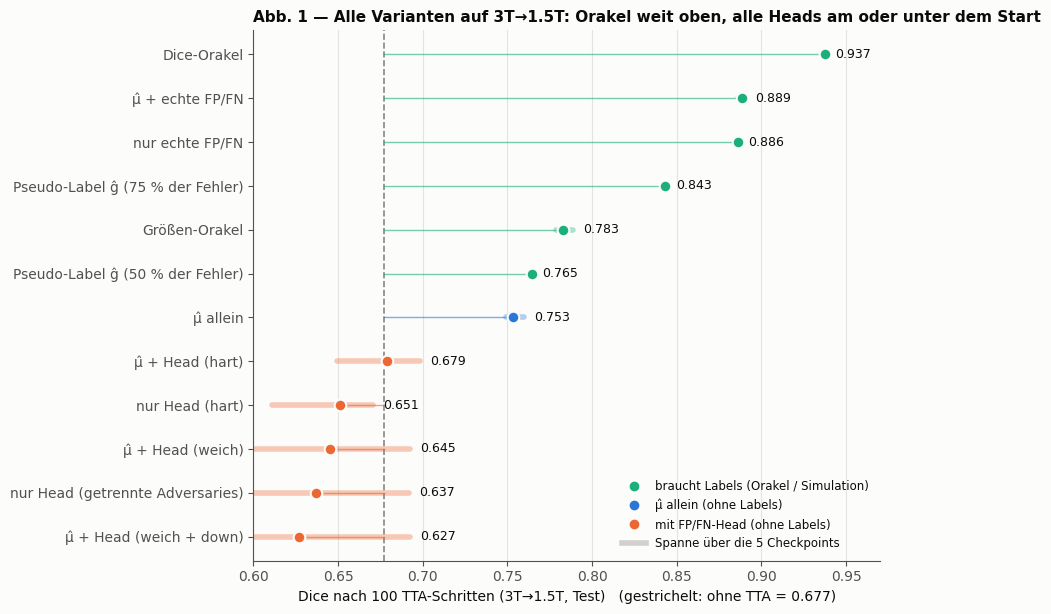

In [2]:
OVERVIEW = [
    ('Dice-Orakel', 'latent_tta_oracle', 'Orakel'),
    ('μ̂ + echte FP/FN', 'latent_tta_mu_fpfn_joint_w1.0', 'Orakel'),
    ('nur echte FP/FN', 'latent_tta_fpfnonly_oracle', 'Orakel'),
    ('Pseudo-Label ĝ (75 % der Fehler)', 'latent_tta_pseudo_recall0.75', 'Orakel'),
    ('Pseudo-Label ĝ (50 % der Fehler)', 'latent_tta_pseudo_recall0.5', 'Orakel'),
    ('Größen-Orakel', 'latent_tta_mu_size_w1.0', 'Orakel'),
    ('μ̂ allein', 'latent_tta_prenorm', 'ohne Labels'),
    ('μ̂ + Head (hart)', 'latent_tta_mu_fpfnhead_w1.0', 'ohne Labels'),
    ('μ̂ + Head (weich)', 'latent_tta_mu_fpfnheadsoft_w1.0', 'ohne Labels'),
    ('μ̂ + Head (weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0', 'ohne Labels'),
    ('nur Head (hart)', 'latent_tta_fpfnonly_head', 'ohne Labels'),
    ('nur Head (getrennte Adversaries)', 'latent_tta_fpfnonly_head_fpfnsplit', 'ohne Labels'),
]
rows = []
for name, run, grp in OVERVIEW:
    v = after_per_ckpt(run, T15)
    if v:
        rows.append((name, grp, np.mean(v), min(v), max(v)))
rows.sort(key=lambda r: r[2])
start = before_dice(T15)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(rows) + 1.2))
for i, (name, grp, m, lo, hi) in enumerate(rows):
    c = C_ORACLE if grp == 'Orakel' else (C_MU if name == 'μ̂ allein' else C_HEAD)
    ax.plot([lo, hi], [i, i], color=c, lw=4, alpha=0.35, solid_capstyle='round')
    ax.plot([start, m], [i, i], color=c, lw=1, alpha=0.6)
    ax.scatter(m, i, s=70, color=c, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.text(max(m, hi) + 0.006, i, f'{m:.3f}', va='center', fontsize=9)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
start_line(ax, start, 'Dice nach 100 TTA-Schritten (3T→1.5T, Test)')
ax.set_xlim(0.6, 0.97); ax.grid(axis='y', visible=False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=C_ORACLE, label='braucht Labels (Orakel / Simulation)'),
                   Line2D([], [], marker='o', ls='', color=C_MU, label='μ̂ allein (ohne Labels)'),
                   Line2D([], [], marker='o', ls='', color=C_HEAD, label='mit FP/FN-Head (ohne Labels)'),
                   Line2D([], [], color=NEUTRAL, lw=4, alpha=0.6, label='Spanne über die 5 Checkpoints')],
          loc='lower right', fontsize=8.5)
ax.set_title('Abb. 1 — Alle Varianten auf 3T→1.5T: Orakel weit oben, alle Heads am oder unter dem Start', loc='left')
fig.tight_layout()

Alles in Grün braucht Labels und zeigt nur, was ein perfektes (bzw. simuliertes) Signal bringen
*könnte*. Blau (μ̂ allein) und Orange (mit FP/FN-Head) sind einsetzbar. Von den einsetzbaren
Varianten ist nur μ̂ allein besser als ohne TTA; jede Variante mit FP/FN-Head landet am Start oder
darunter.

## 1 · Echte FP/FN als Signal (Orakel, alle Splits)

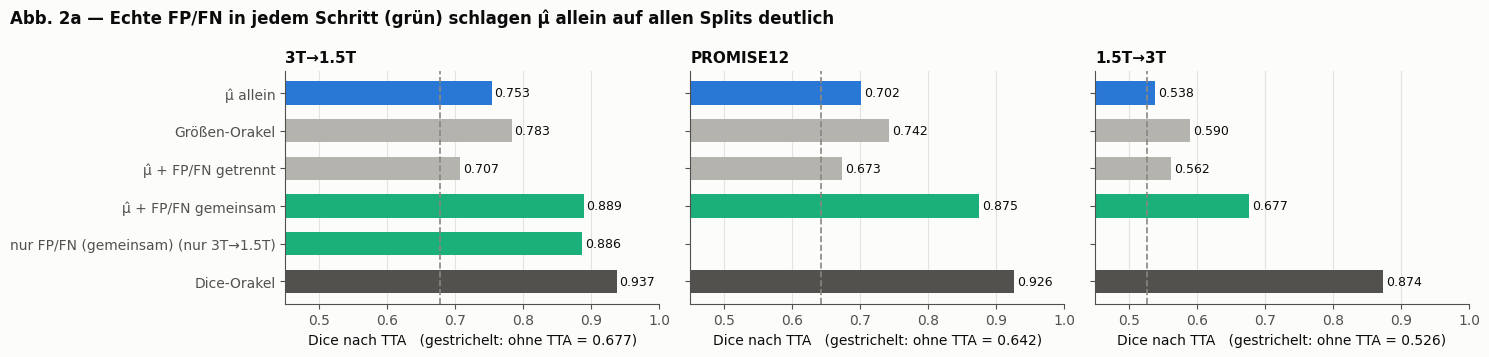

In [3]:
S1 = [('μ̂ allein', 'latent_tta_prenorm', C_MU),
      ('Größen-Orakel', 'latent_tta_mu_size_w1.0', NEUTRAL),
      ('μ̂ + FP/FN getrennt', 'latent_tta_mu_fpfn_w1.0', NEUTRAL),
      ('μ̂ + FP/FN gemeinsam', 'latent_tta_mu_fpfn_joint_w1.0', C_ORACLE),
      ('nur FP/FN (gemeinsam)', 'latent_tta_fpfnonly_oracle', C_ORACLE),
      ('Dice-Orakel', 'latent_tta_oracle', REF)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
names = [n if all(tta_files(r, s) for s in SPLIT_ORDER) else f'{n} (nur 3T→1.5T)' for n, r, _ in S1]
for ax, s in zip(axes, SPLIT_ORDER):
    vals, cols = [], []
    for name, run, c in S1:
        v = after_per_ckpt(run, s)
        vals.append(np.mean(v) if v else 0)
        cols.append(c)
    y = np.arange(len(names))
    bars = ax.barh(y, vals, color=cols, height=0.62)
    label_bars(ax, [b for b, v in zip(bars, vals) if v > 0])
    start_line(ax, before_dice(s))
    ax.set_yticks(y, names); ax.invert_yaxis()
    ax.set_xlim(0.45, 1.0); ax.grid(axis='y', visible=False)
    ax.set_title(SPLITS[s], loc='left')
fig.suptitle('Abb. 2a — Echte FP/FN in jedem Schritt (grün) schlagen μ̂ allein auf allen Splits deutlich', x=0.01, ha='left')
fig.tight_layout()

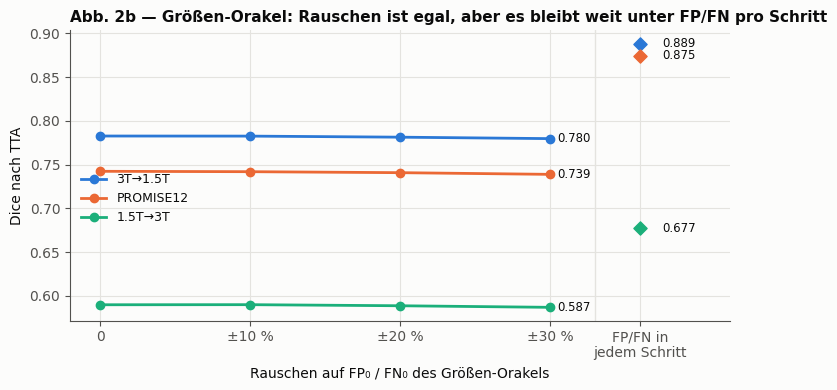

In [4]:
NOISE = [(0.0, 'latent_tta_mu_size_w1.0'), (0.1, 'latent_tta_mu_size_w1.0_noise0.1'),
         (0.2, 'latent_tta_mu_size_w1.0_noise0.2'), (0.3, 'latent_tta_mu_size_w1.0_noise0.3')]
fig, ax = plt.subplots(figsize=(7.5, 4))
for s, c in zip(SPLIT_ORDER, (BLUE, ORANGE, AQUA)):
    xs, ys = zip(*[(n, np.mean(after_per_ckpt(r, s))) for n, r in NOISE if after_per_ckpt(r, s)])
    ax.plot(xs, ys, color=c, marker='o', label=SPLITS[s])
    joint = np.mean(after_per_ckpt('latent_tta_mu_fpfn_joint_w1.0', s))
    ax.scatter([0.36], [joint], marker='D', s=45, color=c, zorder=3)
    ax.text(0.375, joint, f'{joint:.3f}', va='center', fontsize=8.5)
    ax.text(0.305, ys[-1], f'{ys[-1]:.3f}', va='center', fontsize=8.5)
ax.axvline(0.33, color=GRID, lw=1)
ax.set_xticks([0, 0.1, 0.2, 0.3, 0.36], ['0', '±10 %', '±20 %', '±30 %', 'FP/FN in\njedem Schritt'])
ax.set_xlabel('Rauschen auf FP₀ / FN₀ des Größen-Orakels'); ax.set_ylabel('Dice nach TTA')
ax.set_xlim(-0.02, 0.42)
ax.legend(loc='center left', bbox_to_anchor=(0.0, 0.42), fontsize=9)
ax.set_title('Abb. 2b — Größen-Orakel: Rauschen ist egal, aber es bleibt weit unter FP/FN pro Schritt', loc='left')
fig.tight_layout()

- Mit den echten FP/FN in jedem Schritt (grün) steigt der Dice auf allen Splits stark, und
  ohne μ̂ (nur FP/FN) ist es genauso gut wie mit μ̂ — es gibt also auch kein λ abzustimmen.
- Das **Größen-Orakel** kennt FP/FN nur einmal vor der TTA und gibt damit nur eine Zielgröße vor.
  Es bringt etwas über μ̂ allein, bleibt aber weit unter FP/FN pro Schritt, und ±30 % Rauschen
  ändert fast nichts. Die *Zahl* ist also nicht das Entscheidende — der Gradient von FP = Σp(1−g)
  nach p ist die Label-Karte selbst und sagt jedem Pixel, in welche Richtung es muss.

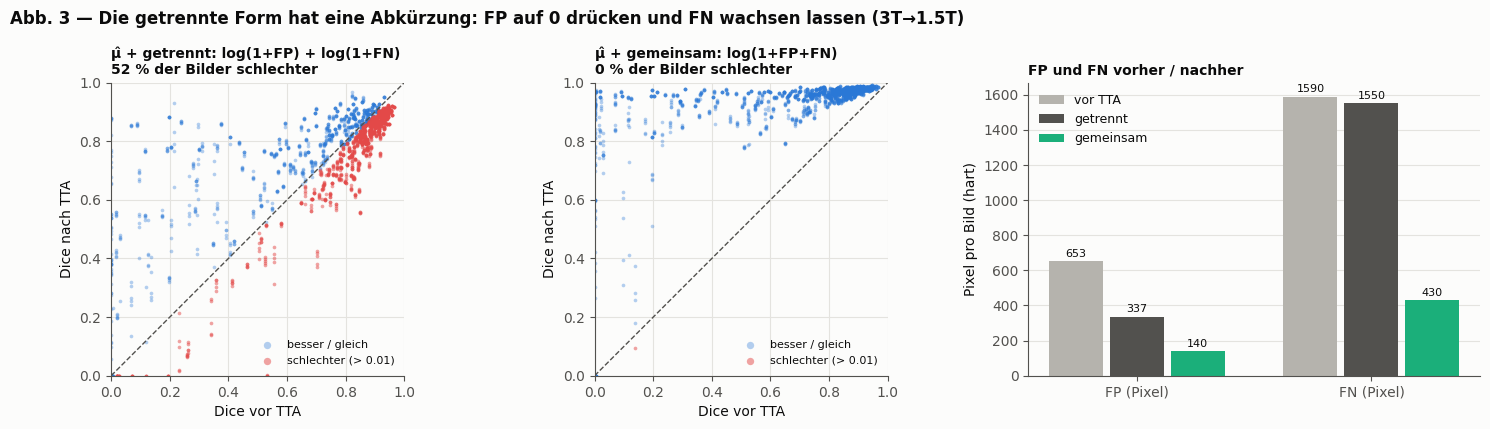

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1, 1, 1.15]})
for ax, (name, run) in zip(axes[:2], [('getrennt: log(1+FP) + log(1+FN)', 'latent_tta_mu_fpfn_w1.0'),
                                       ('gemeinsam: log(1+FP+FN)', 'latent_tta_mu_fpfn_joint_w1.0')]):
    es = evals(run, T15)
    b = torch.cat([e['dice_before'].float() for e in es]).numpy()
    a = torch.cat([e['dice_after'].float() for e in es]).numpy()
    worse = a < b - 0.01
    ax.scatter(b[~worse], a[~worse], s=7, alpha=0.35, color=BLUE, linewidths=0, label='besser / gleich')
    ax.scatter(b[worse], a[worse], s=7, alpha=0.5, color=RED, linewidths=0, label='schlechter (> 0.01)')
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color=INK2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel('Dice vor TTA'); ax.set_ylabel('Dice nach TTA')
    ax.set_title(f'μ̂ + {name}\n{100 * worse.mean():.0f} % der Bilder schlechter', loc='left', fontsize=10)
    ax.legend(loc='lower right', fontsize=8, markerscale=2)
ax = axes[2]
groups = [('vor TTA', None, NEUTRAL), ('getrennt', 'latent_tta_mu_fpfn_w1.0', REF),
          ('gemeinsam', 'latent_tta_mu_fpfn_joint_w1.0', C_ORACLE)]
ref = tta_row('latent_tta_mu_fpfn_w1.0', T15)
w = 0.26
for j, (gname, run, c) in enumerate(groups):
    r = ref if run is None else tta_row(run, T15)
    vals = [r['FP before'], r['FN before']] if run is None else [r['FP after'], r['FN after']]
    bars = ax.bar(np.arange(2) + (j - 1) * w, vals, width=w - 0.03, color=c, label=gname)
    label_bars(ax, bars, fmt='{:.0f}', pad=15, horizontal=False)
ax.set_xticks([0, 1], ['FP (Pixel)', 'FN (Pixel)'])
ax.set_ylabel('Pixel pro Bild (hart)'); ax.grid(axis='x', visible=False)
ax.legend(fontsize=9); ax.set_title('FP und FN vorher / nachher', loc='left', fontsize=10)
fig.suptitle('Abb. 3 — Die getrennte Form hat eine Abkürzung: FP auf 0 drücken und FN wachsen lassen (3T→1.5T)',
             x=0.01, ha='left')
fig.tight_layout()

log(1+FP) + log(1+FN) = log((1+FP)(1+FN)) ist schon minimal, sobald **eine** der beiden Zahlen 0 ist.
Die TTA nimmt diese Abkürzung: Sie entfernt die FP und lässt die FN wachsen — viele Bilder werden
schlechter. log(1+FP+FN) hat diese Abkürzung nicht und bestraft jedes falsche Pixel gleich.

## 2 · Wo selbst das FP/FN-Orakel scheitert: verpasste Prostatas

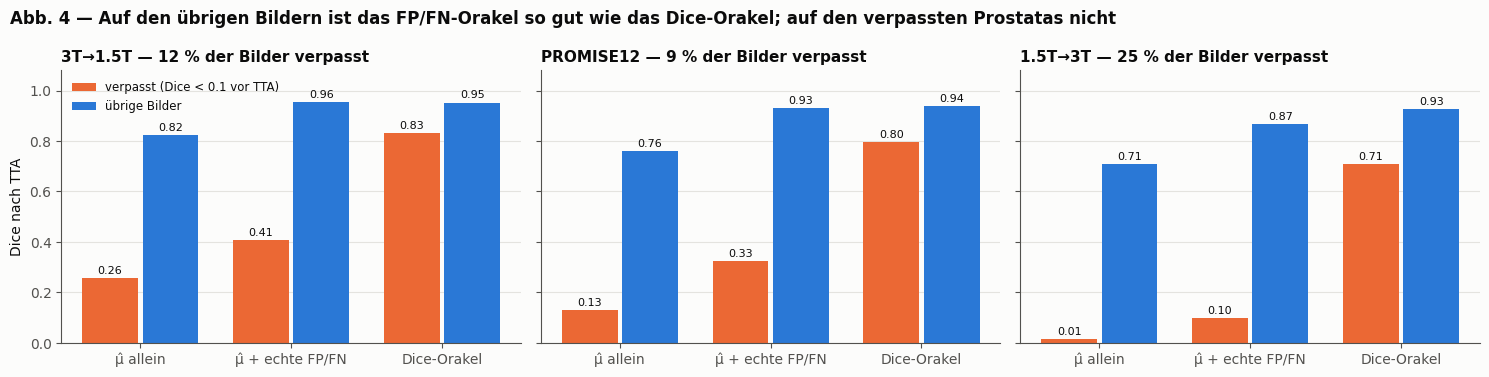

In [6]:
S2 = [('μ̂ allein', 'latent_tta_prenorm'), ('μ̂ + echte FP/FN', 'latent_tta_mu_fpfn_joint_w1.0'),
      ('Dice-Orakel', 'latent_tta_oracle')]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s in zip(axes, SPLIT_ORDER):
    miss_v, rest_v, frac = [], [], None
    for name, run in S2:
        es = evals(run, s)
        b = torch.cat([e['dice_before'].float() for e in es]); a = torch.cat([e['dice_after'].float() for e in es])
        m = b < 0.1
        frac = 100 * float(m.float().mean())
        miss_v.append(float(a[m].mean())); rest_v.append(float(a[~m].mean()))
    x = np.arange(len(S2))
    b1 = ax.bar(x - 0.2, miss_v, 0.37, color=ORANGE, label='verpasst (Dice < 0.1 vor TTA)')
    b2 = ax.bar(x + 0.2, rest_v, 0.37, color=BLUE, label='übrige Bilder')
    label_bars(ax, list(b1) + list(b2), fmt='{:.2f}', pad=0.01, horizontal=False)
    ax.set_xticks(x, [n for n, _ in S2]); ax.set_ylim(0, 1.08); ax.grid(axis='x', visible=False)
    ax.set_title(f'{SPLITS[s]} — {frac:.0f} % der Bilder verpasst', loc='left')
axes[0].set_ylabel('Dice nach TTA'); axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Abb. 4 — Auf den übrigen Bildern ist das FP/FN-Orakel so gut wie das Dice-Orakel; '
             'auf den verpassten Prostatas nicht', x=0.01, ha='left')
fig.tight_layout()

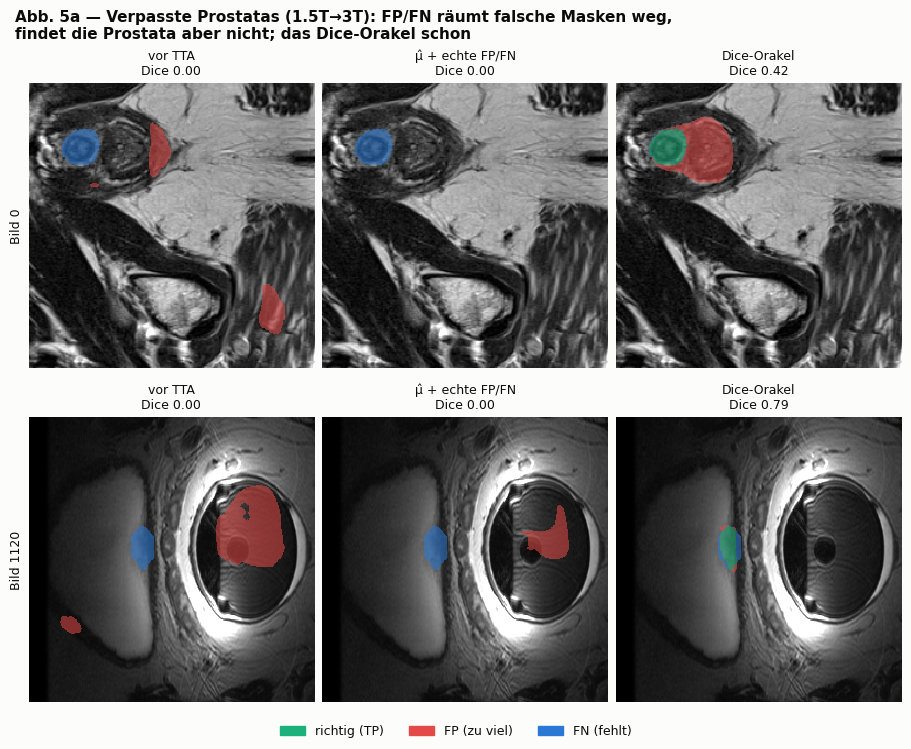

In [7]:
s = 'onepointfivet-to-threet'
es = evals('latent_tta_oracle', s)
idx_all = es[0]['examples']['index'].tolist() if 'examples' in es[0] else []
missed = [i for i in idx_all if float(es[0]['dice_before'][i]) < 0.1]
shown = 0
if missed:
    fig, axes = plt.subplots(len(missed), 3, figsize=(9, 3.4 * len(missed) + 0.6), squeeze=False, layout='constrained')
    for row, idx in zip(axes, missed):
        cols = [('vor TTA', example('latent_tta_oracle', s, idx, 'pred_before')),
                ('μ̂ + echte FP/FN', example('latent_tta_mu_fpfn_joint_w1.0', s, idx)),
                ('Dice-Orakel', example('latent_tta_oracle', s, idx))]
        ref = next(c for _, c in cols if c is not None)
        box = crop_box([ref['target']] + [c['pred'] for _, c in cols if c is not None])
        for ax, (t, c) in zip(row, cols):
            if c is None:
                ax.axis('off'); ax.set_title(f'{t}\n(kein Beispiel gespeichert)', fontsize=9); continue
            error_panel(ax, c['image'], c['pred'], c['target'], t, box)
        row[0].set_ylabel(f'Bild {idx}', fontsize=9)
    fig.legend(handles=ERR_LEGEND, loc='outside lower center', ncol=3, fontsize=9)
    fig.suptitle(f'Abb. 5a — Verpasste Prostatas ({SPLITS[s]}): FP/FN räumt falsche Masken weg,\n'
                 f'findet die Prostata aber nicht; das Dice-Orakel schon', x=0.01, ha='left', fontsize=11)
else:
    print('keine verpasste Prostata unter den gespeicherten Beispielen')

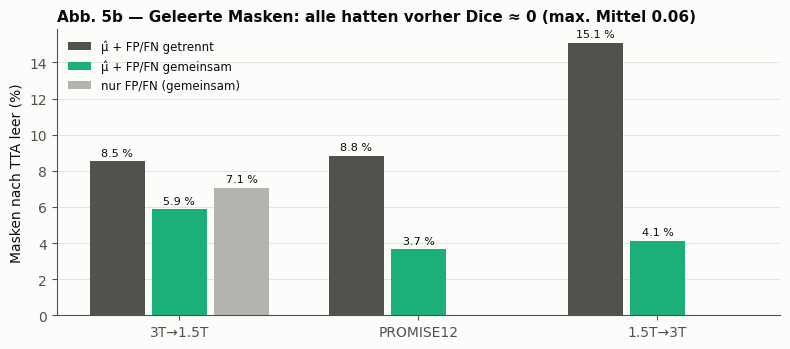

In [8]:
EMPTY = [('μ̂ + FP/FN getrennt', 'latent_tta_mu_fpfn_w1.0', REF), ('μ̂ + FP/FN gemeinsam', 'latent_tta_mu_fpfn_joint_w1.0', C_ORACLE),
         ('nur FP/FN (gemeinsam)', 'latent_tta_fpfnonly_oracle', NEUTRAL)]
et = emptied_table([(n, r) for n, r, _ in EMPTY])
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.26
for j, (name, run, c) in enumerate(EMPTY):
    vals = [et.loc[(SPLITS[s], name), 'emptied %'] if (SPLITS[s], name) in et.index else np.nan for s in SPLIT_ORDER]
    bars = ax.bar(np.arange(3) + (j - 1) * w, np.nan_to_num(vals), w - 0.03, color=c, label=name)
    label_bars(ax, [b for b, v in zip(bars, vals) if not np.isnan(v)], fmt='{:.1f} %', pad=0.2, horizontal=False)
ax.set_xticks(range(3), [SPLITS[s] for s in SPLIT_ORDER]); ax.grid(axis='x', visible=False)
ax.set_ylabel('Masken nach TTA leer (%)'); ax.legend(fontsize=8.5)
before_empty = float(np.nanmax(et['their Dice before (mean)']))
ax.set_title(f'Abb. 5b — Geleerte Masken: alle hatten vorher Dice ≈ 0 (max. Mittel {before_empty:.2f})', loc='left')
fig.tight_layout()

Bei einer verpassten Prostata gilt FP + FN = |P| + |G|. Die Maske wegzuräumen senkt das auf |G| —
und von dort senkt keine *kleine* Änderung der Maske den Wert weiter. Die **leere Maske ist ein
lokales Minimum** von log(1+FP+FN). Weil diese Bilder vorher schon Dice ≈ 0 hatten, kostet das Leeren
keinen Dice, aber das Objective kann eine falsch platzierte Maske nicht *verschieben*. Das erklärt
die große Restlücke auf 1.5T→3T, wo ein Viertel der Prostatas verpasst wird.

## 3 · Wie gut sind die FP/FN-Heads? (ohne TTA)

**Die Head-Varianten.** Alle haben dieselbe Architektur wie der μ̂-Predictor (liest Layer 0, 17 und die
Logits der eingefrorenen U-Net) und sagen log(1+FP) und log(1+FN) voraus, trainiert mit MSE. Pro Schritt
sieht jeder Head 30 saubere Bilder und 30 vom Adversary verschobene Bilder (mit deren echten Zahlen).
Der Adversary verschiebt die Bilder im Eingaberaum so, dass der Head *mehr* Fehler vorhersagt; ein
Controller stellt die Schrittweite so ein, dass der echte Dice dabei um 0.1 fällt.

| Variante | Zielgröße | Adversary |
|---|---|---|
| **hart** (`fpfn`) | Pixel der harten Maske (p > 0.5) | einer, entlang +∇ log(1+FP̂+FN̂), alle 30 Bilder |
| **weich** (`fpfnsoft`) | weiche Zählung Σp(1−g), Σ(1−p)g — genau die Größe des Orakels | wie hart |
| **weich + down** (`fpfnsoftdown`) | weich | wie hart **plus** ein zweiter Adversary in TTA-Richtung (−∇, Head soll *weniger* Fehler melden; Schritt so, dass die Vorhersage um 0.5 in log fällt) — der Head soll lernen, darauf nicht hereinzufallen |
| **getrennte Adv.** (`fpfnsplit`) | hart | zwei Adversaries statt einem: 15 Bilder entlang +∇ log(1+FP̂), 15 entlang +∇ log(1+FN̂), jeder mit eigenem Controller — gedacht, um mehr FN-Beispiele zu erzeugen; Loss weiter über FP **und** FN aller Bilder |
| **getrennte Heads** (`fpfnsepfp` + `fpfnsepfn`) | hart | zwei Netze: der FP-Head lernt nur log(1+FP) mit einem Adversary entlang +∇ log(1+FP̂), der FN-Head nur log(1+FN) entlang +∇ log(1+FN̂); in der TTA kombinierbar (nicht gelaufen). 200 statt 400 Epochen, sonst wie hart |

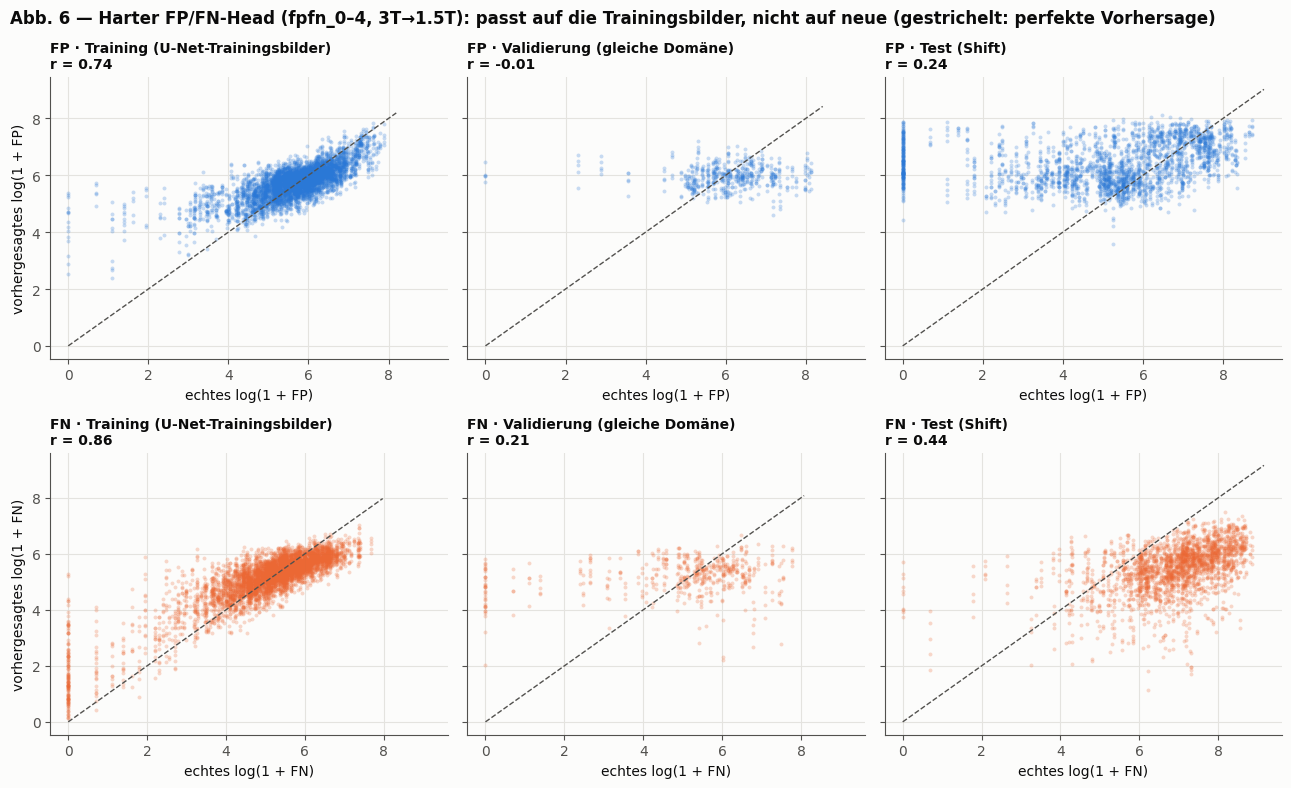

In [9]:
evs = [load_pkl(f)['evaluation'] for f in head_files(T15, 'fpfn')]
DOM_DE = {'train': 'Training (U-Net-Trainingsbilder)', 'val': 'Validierung (gleiche Domäne)', 'test': 'Test (Shift)'}
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex='row', sharey='row')
for j, dom in enumerate(('train', 'val', 'test')):
    pred = torch.cat([ev[f'{T15}_{dom}']['pred'].float() for ev in evs])[:, 0]
    true = torch.cat([ev[f'{T15}_{dom}']['target'].float() for ev in evs])[:, 0]
    for i, (k, name) in enumerate(((0, 'FP'), (1, 'FN'))):
        ax = axes[i, j]
        x, y = true[:, k].numpy(), pred[:, k].numpy()
        ax.scatter(x, y, s=8, alpha=0.25, color=(BLUE if k == 0 else ORANGE), linewidths=0)
        hi = max(x.max(), y.max()) + 0.3
        ax.plot([0, hi], [0, hi], ls='--', lw=1, color=INK2)
        r = np.corrcoef(x, y)[0, 1]
        ax.set_title(f'{name} · {DOM_DE[dom]}\nr = {r:.2f}', fontsize=10, loc='left')
        ax.set_xlabel(f'echtes log(1 + {name})')
        if j == 0:
            ax.set_ylabel(f'vorhergesagtes log(1 + {name})')
fig.suptitle('Abb. 6 — Harter FP/FN-Head (fpfn_0–4, 3T→1.5T): passt auf die Trainingsbilder, nicht auf neue '
             '(gestrichelt: perfekte Vorhersage)', x=0.01, ha='left')
fig.tight_layout()

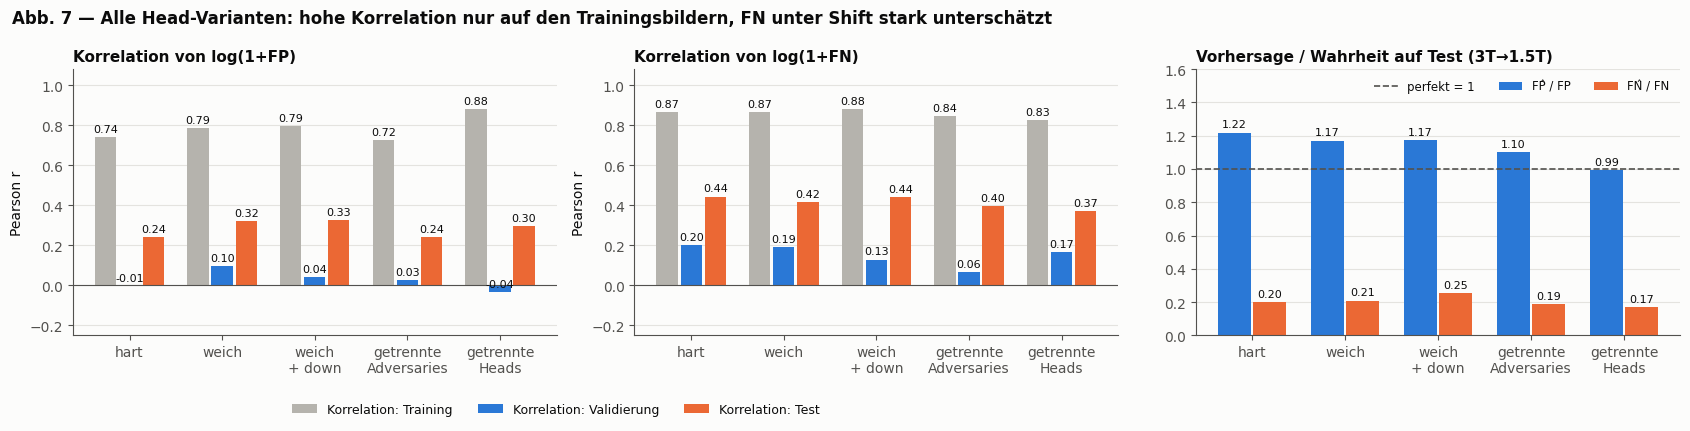

In [10]:
HEADS = [('hart', T15, 'fpfn'), ('weich', T15, 'fpfnsoft'), ('weich + down', T15, 'fpfnsoftdown'),
         ('getrennte Adv.', T15, 'fpfnsplit')]
TICK = ['hart', 'weich', 'weich\n+ down', 'getrennte\nAdversaries', 'getrennte\nHeads']
ht = head_table(HEADS)
# getrennte Heads: FP-Metriken vom FP-Head fpfnsepfp_k, FN-Metriken vom FN-Head fpfnsepfn_k
sep = head_table([('FP-Head', T15, 'fpfnsepfp'), ('FN-Head', T15, 'fpfnsepfn')])
for dom in ('train', 'val', 'test'):
    fp_row, fn_row = sep.loc[(SPLITS[T15], 'FP-Head', dom)], sep.loc[(SPLITS[T15], 'FN-Head', dom)]
    row = {c: (fp_row[c] if 'FP' in c else fn_row[c] if 'FN' in c else np.nan) for c in sep.columns}
    row.update({'U-Net Dice': fp_row['U-Net Dice'], 'n heads': fp_row['n heads']})
    ht.loc[(SPLITS[T15], 'getrennte Heads', dom), :] = pd.Series(row)
HEADS_PLOT = HEADS + [('getrennte Heads', T15, None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.1))
DOM_C = {'train': NEUTRAL, 'val': BLUE, 'test': ORANGE}
DOM_L = {'train': 'Training', 'val': 'Validierung', 'test': 'Test'}
x = np.arange(len(HEADS_PLOT)); w = 0.26
for ax, metric, name in ((axes[0], 'r log FP', 'FP'), (axes[1], 'r log FN', 'FN')):
    for j, dom in enumerate(('train', 'val', 'test')):
        vals = [ht.loc[(SPLITS[T15], h, dom), metric] for h, _, _ in HEADS_PLOT]
        bars = ax.bar(x + (j - 1) * w, vals, w - 0.03, color=DOM_C[dom], label=DOM_L[dom])
        label_bars(ax, bars, fmt='{:.2f}', pad=0.015, horizontal=False)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(x, TICK); ax.set_ylim(-0.25, 1.08); ax.grid(axis='x', visible=False)
    ax.set_title(f'Korrelation von log(1+{name})', loc='left'); ax.set_ylabel('Pearson r')
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, [f'Korrelation: {l}' for l in l_], fontsize=9, loc='lower center', ncol=3, bbox_to_anchor=(0.33, -0.04))
ax = axes[2]
for j, (metric, name, c) in enumerate((('FP_hat / FP', 'FP̂ / FP', BLUE), ('FN_hat / FN', 'FN̂ / FN', ORANGE))):
    vals = [ht.loc[(SPLITS[T15], h, 'test'), metric] for h, _, _ in HEADS_PLOT]
    bars = ax.bar(x + (j - 0.5) * 0.38, vals, 0.35, color=c, label=name)
    label_bars(ax, bars, fmt='{:.2f}', pad=0.02, horizontal=False)
ax.axhline(1, color=INK2, ls='--', lw=1.2, label='perfekt = 1')
ax.set_xticks(x, TICK); ax.grid(axis='x', visible=False); ax.set_ylim(0, 1.6)
ax.set_title('Vorhersage / Wahrheit auf Test (3T→1.5T)', loc='left'); ax.legend(fontsize=8.5, loc='upper right', ncol=3)
fig.suptitle('Abb. 7 — Alle Head-Varianten: hohe Korrelation nur auf den Trainingsbildern, FN unter Shift stark unterschätzt',
             x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.05, 1, 1))

- Der Head lernt die Fehler der U-Net auf **genau den Bildern, auf denen die U-Net trainiert wurde**.
  Dort macht die U-Net kaum und andere Fehler als auf neuen Bildern (U-Net-Dice dort 0.92–0.95 statt
  0.86 auf Validierung). Auf neuen Bildern derselben Domäne ist die Korrelation praktisch weg.
- Unter Shift unterschätzt jede Variante FN etwa um Faktor 5 und überschätzt FP — die Reihenfolge der
  Fehlerarten ist vertauscht (wahr: FN ≫ FP).
- **Getrennte Heads** (ein Head nur für FP, einer nur für FN, je mit eigenem Adversary): Der FP-Head passt
  besser auf die Trainingsbilder und trifft auf dem Test die FP-Menge im Mittel, bleibt auf der
  Validierung aber bei r ≈ 0; der FN-Head ist überall leicht schlechter als der gemeinsame Head und
  unterschätzt FN unter Shift genauso. Die Trennung ändert am Kernproblem nichts.

### 3b · Trainingsverlauf: wann waren die Heads am besten?

Validierungsmetriken aller Head-Trainings aus wandb (Projekt `MIDL-Extension`), einmal abgerufen und
in `results/fpfn_head/wandb_val_history.csv` gespeichert, damit das Notebook ohne wandb-Zugang läuft.
Der Abruf steht auskommentiert in der nächsten Zelle. Die Epoche des tatsächlich verwendeten
Checkpoints steht im Dateinamen unter `pre-trained/fpfn-heads/`.

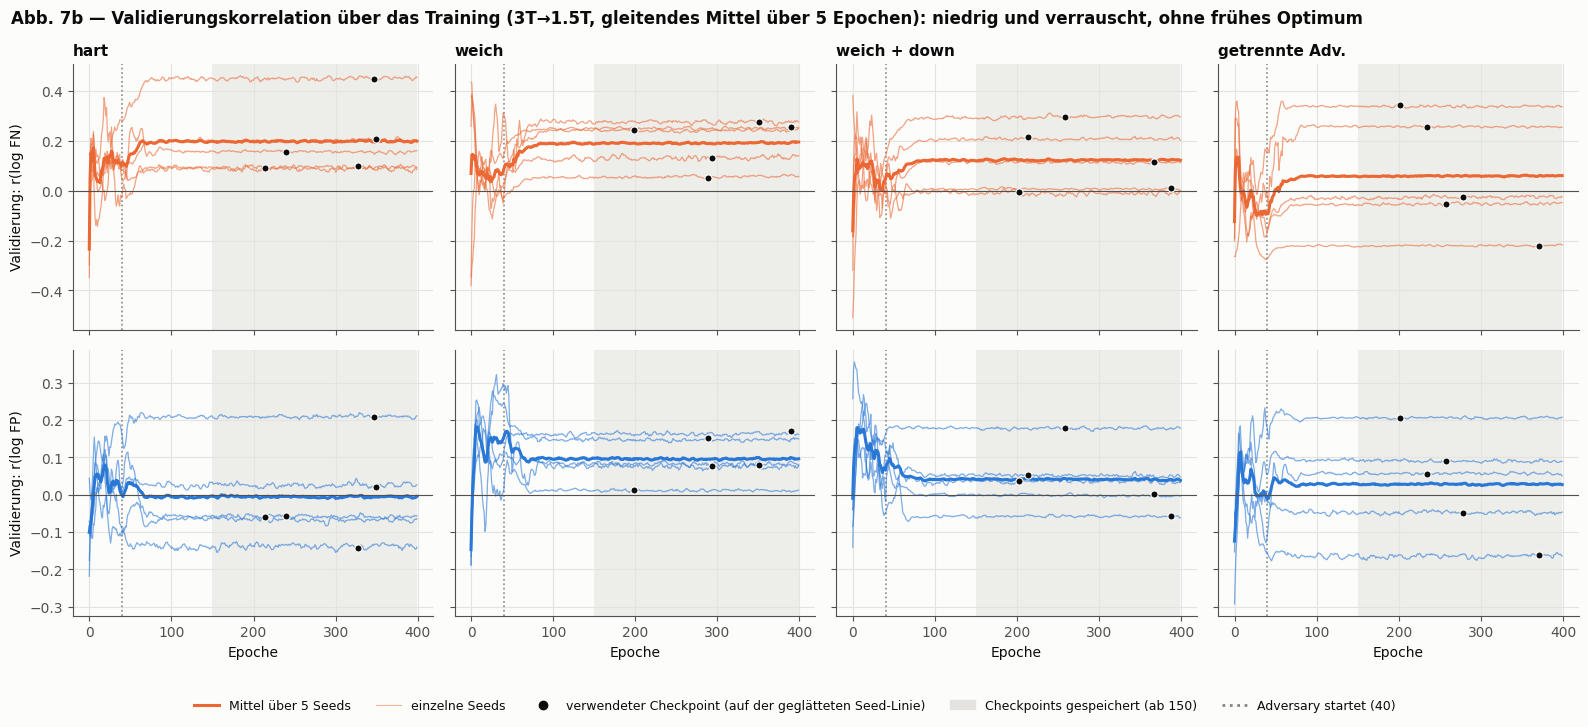

In [11]:
# Abruf (einmalig, braucht wandb-Login):
# import wandb, re
# api = wandb.Api(timeout=60); latest = {}
# for r in api.runs('golop-university-of-bonn/MIDL-Extension', filters={'display_name': {'$regex': 'fpfn'}}):
#     m = re.search(r'^pmri_(.+?)_fpfn_predictor.*mse-(fpfn\w*?)_(\d)_(\d{4}-\d\d-\d\d-\d\d-\d\d)$', r.name)
#     if m and ((key := (m[1], m[2], int(m[3]))) not in latest or m[4] > latest[key][0]):
#         latest[key] = (m[4], r)
# keys = ['epoch', 'val_corr_log_fn', 'val_corr_log_fp', 'val_loss', 'val_loss_clean', 'val_mae_log_fn', 'val_mae_log_fp']
# hist = pd.concat([r.history(keys=keys, samples=5000, pandas=True).dropna(subset=['val_corr_log_fn'])
#                   .groupby('epoch').last().reset_index().assign(split=s, variant=v, seed=k, run_id=r.id, run_name=r.name)
#                   for (s, v, k), (_, r) in sorted(latest.items())], ignore_index=True)
# hist.to_csv(RES / 'fpfn_head' / 'wandb_val_history.csv', index=False)

hist = pd.read_csv(RES / 'fpfn_head' / 'wandb_val_history.csv')
CKPT_START, ADV_START = 150, 40          # ckpt_start_epoch / adversarial_skip_epochs aller Head-Trainings
used = []
for f in (ROOT / 'pre-trained' / 'fpfn-heads').glob('*.ckpt'):
    m = re.search(r'^pmri_(.+?)_fpfn_predictor.*mse-(fpfn\w*?)_(\d)_.*val-epoch=(\d+)', f.name)
    if m:
        used.append({'split': m[1], 'variant': m[2], 'seed': int(m[3]), 'used_epoch': int(m[4])})
used = pd.DataFrame(used)

def at_epoch(h, ep, col):
    return float(h.set_index('epoch').loc[ep, col])

VARIANTS_3B = [('fpfn', 'hart'), ('fpfnsoft', 'weich'), ('fpfnsoftdown', 'weich + down'), ('fpfnsplit', 'getrennte Adv.')]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey='row')
for j, (v, vname) in enumerate(VARIANTS_3B):
    sub = hist[(hist.split == T15) & (hist.variant == v)]
    for i, (col, name, c) in enumerate((('val_corr_log_fn', 'FN', ORANGE), ('val_corr_log_fp', 'FP', BLUE))):
        ax = axes[i, j]
        ax.axvspan(CKPT_START, sub.epoch.max(), color=GRID, alpha=0.6, lw=0)
        ax.axvline(ADV_START, color=START, ls=':', lw=1.2)
        for k, h in sub.groupby('seed'):
            h = h.sort_values('epoch')
            smooth = h[col].rolling(5, min_periods=1).mean().to_numpy()
            ax.plot(h.epoch, smooth, color=c, lw=0.9, alpha=0.6)
            u = used[(used.split == T15) & (used.variant == v) & (used.seed == k)]
            if len(u):
                ep = int(u.used_epoch.iloc[0])
                ax.scatter(ep, smooth[np.searchsorted(h.epoch.to_numpy(), ep)], s=26, color=INK, zorder=3, edgecolor=SURFACE, linewidth=0.8)
        mean = sub.groupby('epoch')[col].mean().rolling(5, min_periods=1).mean()
        ax.plot(mean.index, mean.values, color=c, lw=2.2)
        ax.axhline(0, color=INK2, lw=0.8)
        if i == 0:
            ax.set_title(vname, loc='left')
        if j == 0:
            ax.set_ylabel(f'Validierung: r(log {name})')
        if i == 1:
            ax.set_xlabel('Epoche')
fig.legend(handles=[Line2D([], [], color=ORANGE, lw=2.2, label='Mittel über 5 Seeds'),
                           Line2D([], [], color=ORANGE, lw=0.8, alpha=0.5, label='einzelne Seeds'),
                           Line2D([], [], marker='o', ls='', color=INK, label='verwendeter Checkpoint (auf der geglätteten Seed-Linie)'),
                           mpatches.Patch(color=GRID, label='Checkpoints gespeichert (ab 150)'),
                           Line2D([], [], color=START, ls=':', label='Adversary startet (40)')],
           fontsize=9, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Abb. 7b — Validierungskorrelation über das Training (3T→1.5T, gleitendes Mittel über 5 Epochen): '
             'niedrig und verrauscht, ohne frühes Optimum', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.03, 1, 1))

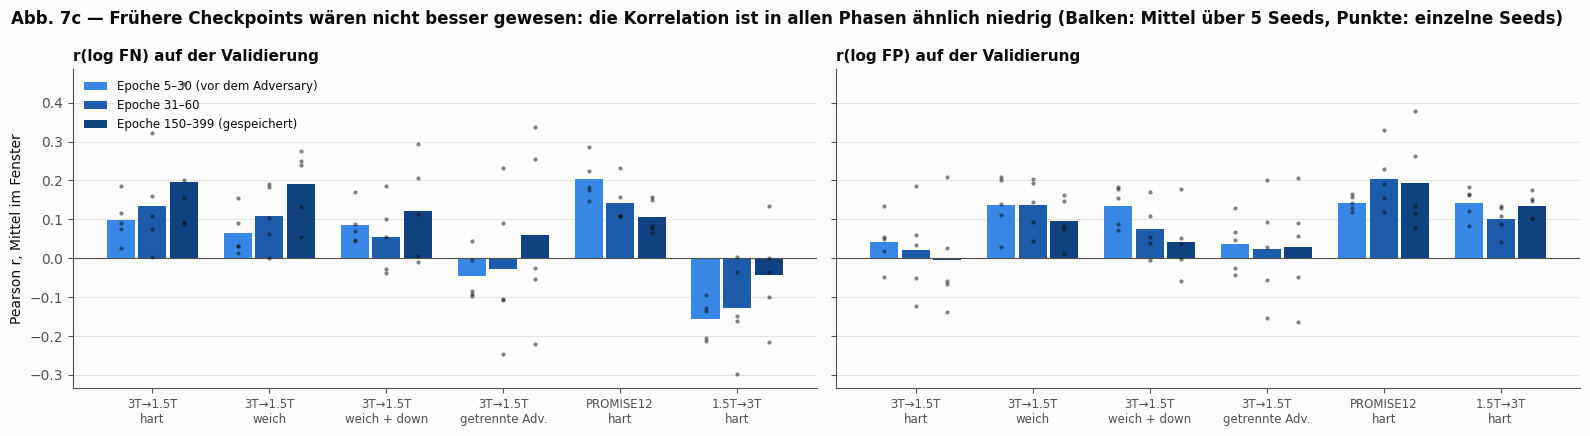

In [12]:
# Mittlere Validierungskorrelation pro Seed in festen Epochenfenstern (keine Auswahl einzelner Epochen:
# auf 103 Bildern schwankt r von Epoche zu Epoche um ~0.1, ein Maximum über viele Epochen ist Rauschen)
WINDOWS = [((5, 30), 'Epoche 5–30 (vor dem Adversary)'), ((31, 60), 'Epoche 31–60'), ((150, 399), 'Epoche 150–399 (gespeichert)')]
combos = [(T15, v, n) for v, n in VARIANTS_3B] + [('promise12', 'fpfn', 'hart'), ('onepointfivet-to-threet', 'fpfn', 'hart')]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), sharey=True)
for ax, (col, name) in zip(axes, (('val_corr_log_fn', 'FN'), ('val_corr_log_fp', 'FP'))):
    x = np.arange(len(combos)); w = 0.27
    for j, ((lo, hi), wname) in enumerate(WINDOWS):
        per_seed = [hist[(hist.split == s) & (hist.variant == v) & hist.epoch.between(lo, hi)].groupby('seed')[col].mean()
                    for s, v, _ in combos]
        means = [p.mean() for p in per_seed]
        bars = ax.bar(x + (j - 1) * w, means, w - 0.03, color=SEQ[2 - j] if j < 2 else SEQ[0], alpha=1.0, label=wname)
        for xi, p in zip(x, per_seed):
            ax.scatter(np.full(len(p), xi + (j - 1) * w), p, s=9, color=INK, alpha=0.5, zorder=3, linewidths=0)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(x, [f'{SPLITS[s]}\n{n}' for s, _, n in combos], fontsize=8.5); ax.grid(axis='x', visible=False)
    ax.set_title(f'r(log {name}) auf der Validierung', loc='left')
axes[0].set_ylabel('Pearson r, Mittel im Fenster')
axes[0].legend(fontsize=8.5, loc='upper left')
fig.suptitle('Abb. 7c — Frühere Checkpoints wären nicht besser gewesen: die Korrelation ist in allen Phasen ähnlich niedrig '
             '(Balken: Mittel über 5 Seeds, Punkte: einzelne Seeds)',
             x=0.01, ha='left')
fig.tight_layout()

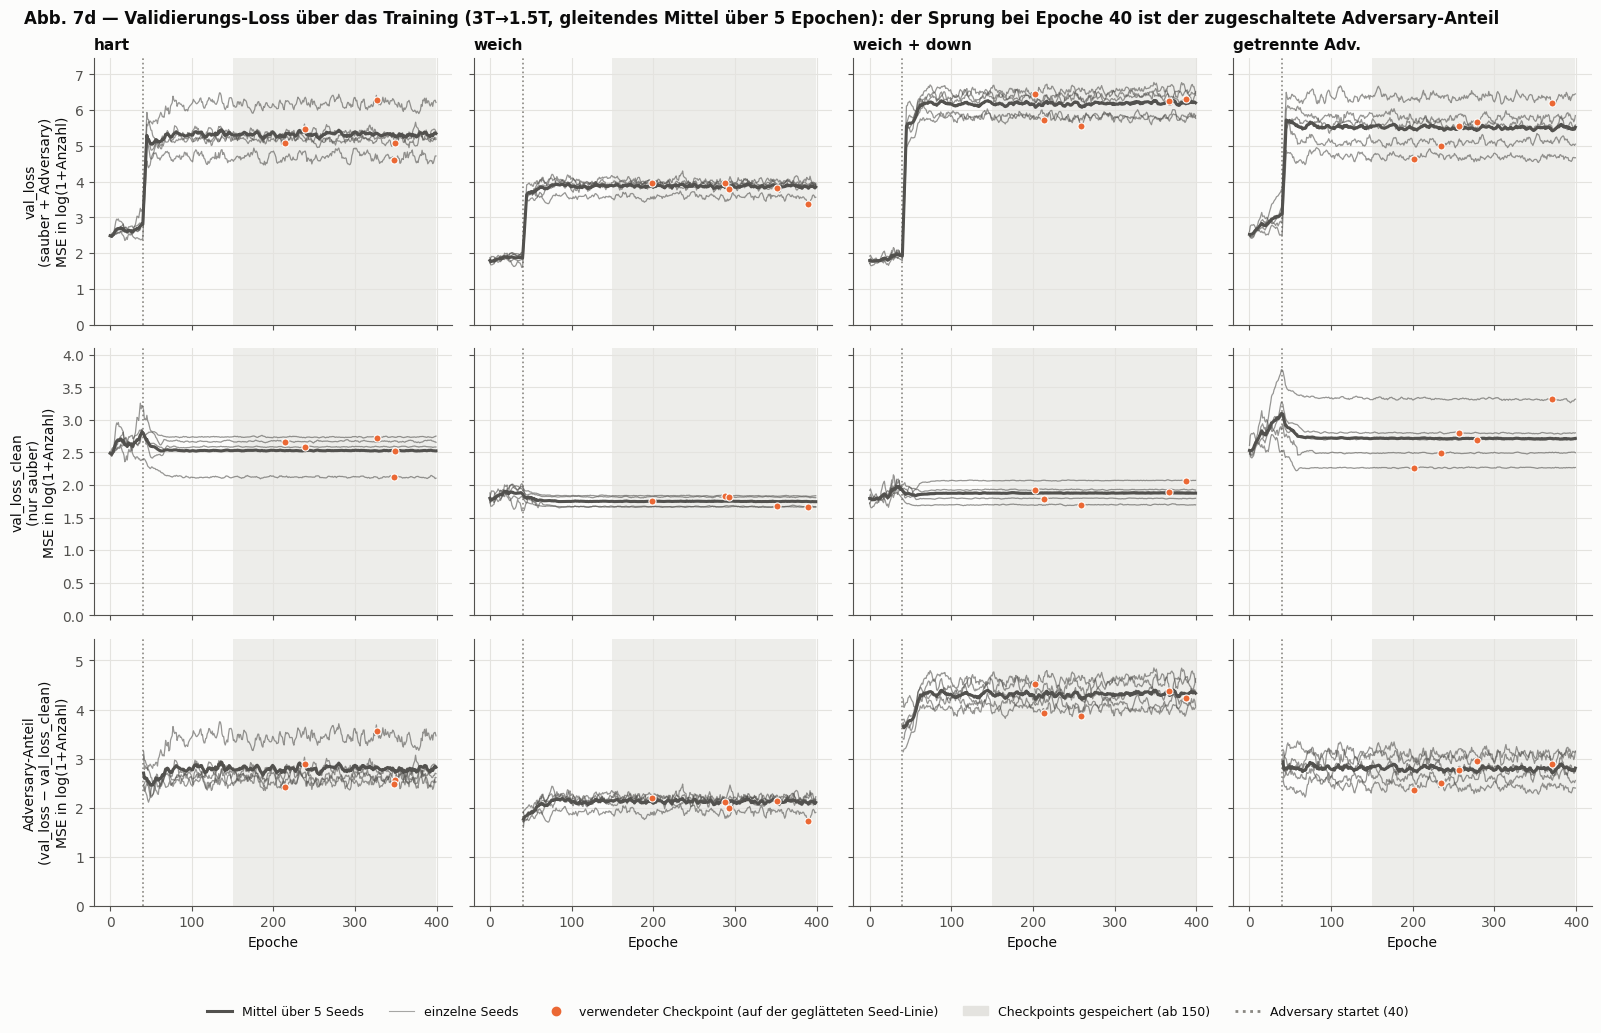

In [13]:
# val_loss = MSE auf sauberen Bildern + (ab Epoche 41) MSE auf den Adversary-Bildern (+ bei 'weich + down' der
# Down-Adversary); danach wurden die Checkpoints ausgewählt (monitor='val_loss').  val_loss_clean = nur sauber,
# Adversary-Anteil = val_loss − val_loss_clean (vor Epoche 41 nicht Teil von val_loss).
hist['val_loss_adv_part'] = (hist.val_loss - hist.val_loss_clean).where(hist.epoch > ADV_START)
LOSS_ROWS = (('val_loss', 'val_loss\n(sauber + Adversary)'), ('val_loss_clean', 'val_loss_clean\n(nur sauber)'),
             ('val_loss_adv_part', 'Adversary-Anteil\n(val_loss − val_loss_clean)'))
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey='row')
for j, (v, vname) in enumerate(VARIANTS_3B):
    sub = hist[(hist.split == T15) & (hist.variant == v)]
    for i, (col, name) in enumerate(LOSS_ROWS):
        ax = axes[i, j]
        ax.axvspan(CKPT_START, sub.epoch.max(), color=GRID, alpha=0.6, lw=0)
        ax.axvline(ADV_START, color=START, ls=':', lw=1.2)
        for k, h in sub.groupby('seed'):
            h = h.sort_values('epoch')
            smooth = h[col].rolling(5, min_periods=1).mean().to_numpy()
            ax.plot(h.epoch, smooth, color=REF, lw=0.9, alpha=0.6)
            u = used[(used.split == T15) & (used.variant == v) & (used.seed == k)]
            if len(u):
                ep = int(u.used_epoch.iloc[0])
                ax.scatter(ep, smooth[np.searchsorted(h.epoch.to_numpy(), ep)], s=26, color=ORANGE, zorder=3, edgecolor=SURFACE, linewidth=0.8)
        mean = sub.groupby('epoch')[col].mean().rolling(5, min_periods=1).mean()
        ax.plot(mean.index, mean.values, color=REF, lw=2.2)
        if i == 0:
            ax.set_title(vname, loc='left')
        if j == 0:
            ax.set_ylabel(f'{name}\nMSE in log(1+Anzahl)')
        if i == len(LOSS_ROWS) - 1:
            ax.set_xlabel('Epoche')
for i, (col, _) in enumerate(LOSS_ROWS):
    top = hist[(hist.split == T15) & hist.variant.isin([v for v, _ in VARIANTS_3B])][col].max()
    axes[i, 0].set_ylim(0, 1.05 * top)
fig.legend(handles=[Line2D([], [], color=REF, lw=2.2, label='Mittel über 5 Seeds'),
                    Line2D([], [], color=REF, lw=0.8, alpha=0.5, label='einzelne Seeds'),
                    Line2D([], [], marker='o', ls='', color=ORANGE, label='verwendeter Checkpoint (auf der geglätteten Seed-Linie)'),
                    mpatches.Patch(color=GRID, label='Checkpoints gespeichert (ab 150)'),
                    Line2D([], [], color=START, ls=':', label='Adversary startet (40)')],
           fontsize=9, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Abb. 7d — Validierungs-Loss über das Training (3T→1.5T, gleitendes Mittel über 5 Epochen): '
             'der Sprung bei Epoche 40 ist der zugeschaltete Adversary-Anteil', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.025, 1, 1))

LR in den gespeicherten Checkpoints (3T→1.5T): ['3.16e-09']


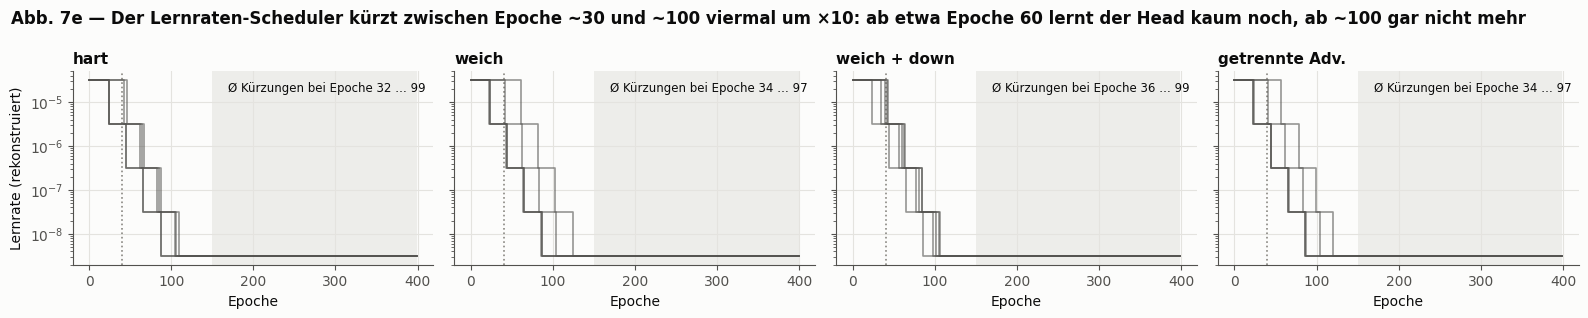

In [14]:
# Lernrate rekonstruiert: ReduceLROnPlateau auf val_loss (factor 0.1, patience 20, threshold 1e-4 rel., eps 1e-8,
# Start-LR 3.16e-5 aus configs/model/fpfn_head.yaml), gefüttert mit den geloggten val_loss-Werten.
# Kontrolle: in den gespeicherten Checkpoints steht lr = 3.16e-9.
LR0 = 3.16e-5
def lr_trace(vals):
    opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=LR0)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', patience=20)
    out = []
    for v in vals:
        out.append(opt.param_groups[0]['lr'])
        sch.step(float(v))
    return np.array(out)
ckpt_lr = {os.path.basename(f): torch.load(f, map_location='cpu', weights_only=False)['optimizer_states'][0]['param_groups'][0]['lr']
           for f in sorted((ROOT / 'pre-trained' / 'fpfn-heads').glob(f'pmri_{T15}_*.ckpt'))}
print('LR in den gespeicherten Checkpoints (3T→1.5T):', sorted({f'{v:.2e}' for v in ckpt_lr.values()}))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, (v, vname) in zip(axes, VARIANTS_3B):
    sub = hist[(hist.split == T15) & (hist.variant == v)]
    ax.axvspan(CKPT_START, sub.epoch.max(), color=GRID, alpha=0.6, lw=0)
    ax.axvline(ADV_START, color=START, ls=':', lw=1.2)
    cuts = []
    for k, h in sub.groupby('seed'):
        h = h.sort_values('epoch')
        lr = lr_trace(h.val_loss)
        ax.step(h.epoch, lr, where='post', color=REF, lw=1.2, alpha=0.6)
        cuts.append(h.epoch.to_numpy()[np.nonzero(np.diff(lr))[0] + 1])
    ax.set_yscale('log'); ax.set_title(vname, loc='left'); ax.set_xlabel('Epoche')
    first, last = np.mean([c[0] for c in cuts]), np.mean([c[-1] for c in cuts])
    ax.text(0.98, 0.95, f'Ø Kürzungen bei Epoche {first:.0f} … {last:.0f}', transform=ax.transAxes, ha='right', va='top', fontsize=8.5)
axes[0].set_ylabel('Lernrate (rekonstruiert)')
fig.suptitle('Abb. 7e — Der Lernraten-Scheduler kürzt zwischen Epoche ~30 und ~100 viermal um ×10: '
             'ab etwa Epoche 60 lernt der Head kaum noch, ab ~100 gar nicht mehr', x=0.01, ha='left')
fig.tight_layout()

- Die Korrelation auf der Validierung (103 Bilder) ist über das ganze Training niedrig, für FN auf
  3T→1.5T etwa 0.05–0.2, und schwankt von Epoche zu Epoche stark (dünne Linien). Es gibt **kein frühes
  Optimum**, das durch `ckpt_start_epoch = 150` verpasst worden wäre; auf 3T→1.5T ist FN spät sogar
  etwas besser als früh. Ein „bestes r“ über alle Epochen herauszusuchen wäre hier nur Rauschen.
- Die Lücke zwischen Training (r ≈ 0.85) und Validierung (Abb. 6, 7) besteht also unabhängig vom
  Zeitpunkt. Die Heads generalisieren grundsätzlich nicht — ein Problem der Trainingsdaten / Zielgröße,
  nicht der Trainingsdauer.
- Der Adversary (ab Epoche 40) verändert die Validierungskorrelation kaum.
- **Checkpoint-Auswahl:** `DelayedModelCheckpoint` aus `model/score_adapter.py` (gemeinsam mit dem
  μ̂-Predictor): `monitor='val_loss'`, `mode='min'`, `save_top_k=1`, aber nur für Epochen ≥ 150
  (`ckpt_start_epoch`). Verwendet wird danach `best_model_path`, also der niedrigste `val_loss` ab
  Epoche 150. Das gilt für alle vier Head-Varianten und alle Splits gleich und ist dieselbe Regel wie beim
  μ̂-Predictor. Grund für die 150 laut Code-Kommentar: erst speichern, wenn Adversary-Pause (40),
  Warm-up (30) und beim μ̂-Predictor der Beta-Abfall (20) vorbei sind, damit nur Werte desselben
  Loss-Typs verglichen werden. Für die Heads (ohne Beta-Abfall) würde Epoche 70 reichen; 150 ist der
  übernommene, vorsichtige Standard.
- **Loss (Abb. 7d):** `val_loss` springt nach Epoche 40 auf etwa das Doppelte, weil ab dann der
  Fehler auf den Adversary-Bildern dazugezählt wird — das ist kein Overfitting. Der saubere Anteil
  `val_loss_clean` ist ab etwa Epoche 60 flach. Deshalb liegt das Minimum von `val_loss` immer vor
  Epoche 40, und eine Auswahl „nach minimalem `val_loss`“ über das ganze Training würde nur Epochen
  ohne Adversary-Anteil bevorzugen. Die Checkpoint-Auswahl ab Epoche 150 vergleicht dagegen
  gleichartige Werte.
- **Lernrate (Abb. 7e) — wichtiger Nebenbefund:** Der LR-Scheduler (`ReduceLROnPlateau`, Patience 20,
  Faktor 0.1) hängt ebenfalls an `val_loss`. Die erste Kürzung kommt schon um Epoche 30, weil `val_loss`
  sein Minimum in den ersten Epochen hat; danach fällt `val_loss` wegen des Adversary-Anteils nie
  wieder unter diesen Wert. Ergebnis: viermal ×0.1, von 3.2e-5 auf 3.2e-9 bis etwa Epoche 100 — genau
  diesen Wert enthalten auch die gespeicherten Checkpoints (Kontrolle oben). Ab etwa Epoche 60 liegt die
  Lernrate 100-fach unter dem Start, ab ~100 lernt der Head nicht mehr. Deshalb sind alle Kurven danach
  flach, und die Epochen 150–400 sind praktisch dasselbe Modell. Der Adversary hat damit nur wenige
  Epochen mit kleiner Lernrate gewirkt. Der μ̂-Predictor nutzt denselben Mechanismus; sein Checkpoint
  (`cleanHalf_0`, 3T→1.5T) enthält ebenfalls lr = 3.2e-9.

### 3c · Zum Vergleich: der μ̂/κ-Predictor

Dieselbe Darstellung für den Score-Predictor, mit dem alle TTA-Läufe gemacht wurden
(`pre_norm_with_logits`, `cleanHalf_0–4`, 3T→1.5T). Er nutzt denselben Trainer: Checkpoint nach
minimalem `val_loss` ab Epoche 150, LR-Scheduler auf `val_loss`, Start-LR 3.16e-5, Patience 20.
Sein `val_loss` ist die Beta-NLL (kann negativ sein): sauberer Anteil `val_plain_nll_regular`, ab
Epoche 41 plus Adversary-Anteil `val_plain_nll_adv`. Verlauf aus wandb, gespeichert in
`results/wandb/mu_predictor_threet-to-onepointfivet_val_history.csv`.

μ̂-Predictor: Checkpoint-Epochen {0: 398, 1: 218, 2: 213, 3: 342, 4: 152} | LR in den Checkpoints ['3.16e-09']


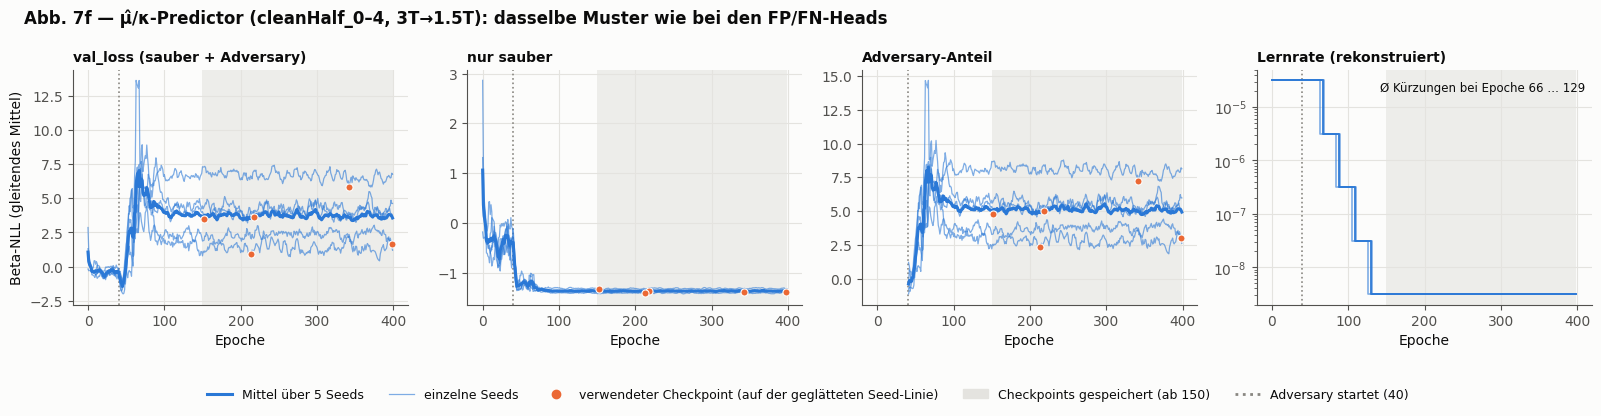

In [15]:
mu_hist = pd.read_csv(RES / 'wandb' / 'mu_predictor_threet-to-onepointfivet_val_history.csv')
mu_hist['adv_part'] = mu_hist.val_plain_nll_adv.where(mu_hist.epoch > ADV_START)
mu_used = {}
for f in (ROOT / 'pre-trained' / 'score-predictors' / 'pre_norm_with_logits').glob(f'pmri_{T15}_*cleanHalf_*val-epoch=*.ckpt'):
    m = re.search(r'cleanHalf_(\d)_.*val-epoch=(\d+)', f.name)
    mu_used[int(m[1])] = (int(m[2]), torch.load(f, map_location='cpu', weights_only=False)['optimizer_states'][0]['param_groups'][0]['lr'])
print('μ̂-Predictor: Checkpoint-Epochen', {k: v[0] for k, v in sorted(mu_used.items())},
      '| LR in den Checkpoints', sorted({f'{v[1]:.2e}' for v in mu_used.values()}))

MU_COLS = (('val_loss', 'val_loss (sauber + Adversary)'), ('val_plain_nll_regular', 'nur sauber'),
           ('adv_part', 'Adversary-Anteil'), ('lr', 'Lernrate (rekonstruiert)'))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True)
cuts = []
for ax, (col, name) in zip(axes, MU_COLS):
    ax.axvspan(CKPT_START, mu_hist.epoch.max(), color=GRID, alpha=0.6, lw=0)
    ax.axvline(ADV_START, color=START, ls=':', lw=1.2)
    curves = []
    for k, h in mu_hist.groupby('seed'):
        h = h.sort_values('epoch')
        if col == 'lr':
            y = lr_trace(h.val_loss)
            cuts.append(h.epoch.to_numpy()[np.nonzero(np.diff(y))[0] + 1])
            ax.step(h.epoch, y, where='post', color=BLUE, lw=1.2, alpha=0.6)
            continue
        y = h[col].rolling(5, min_periods=1).mean().to_numpy()
        curves.append(pd.Series(y, index=h.epoch.to_numpy()))
        ax.plot(h.epoch, y, color=BLUE, lw=0.9, alpha=0.6)
        if k in mu_used:
            ep = mu_used[k][0]
            ax.scatter(ep, y[np.searchsorted(h.epoch.to_numpy(), ep)], s=26, color=ORANGE, zorder=3,
                       edgecolor=SURFACE, linewidth=0.8)
    if curves:
        mean = pd.concat(curves, axis=1).mean(1)
        ax.plot(mean.index, mean.values, color=BLUE, lw=2.2)
    else:
        ax.set_yscale('log')
    ax.set_title(name, loc='left', fontsize=10); ax.set_xlabel('Epoche')
axes[0].set_ylabel('Beta-NLL (gleitendes Mittel)')
axes[3].text(0.98, 0.95, f'Ø Kürzungen bei Epoche {np.mean([c[0] for c in cuts]):.0f} … {np.mean([c[-1] for c in cuts]):.0f}',
             transform=axes[3].transAxes, ha='right', va='top', fontsize=8.5)
fig.legend(handles=[Line2D([], [], color=BLUE, lw=2.2, label='Mittel über 5 Seeds'),
                    Line2D([], [], color=BLUE, lw=0.9, alpha=0.6, label='einzelne Seeds'),
                    Line2D([], [], marker='o', ls='', color=ORANGE, label='verwendeter Checkpoint (auf der geglätteten Seed-Linie)'),
                    mpatches.Patch(color=GRID, label='Checkpoints gespeichert (ab 150)'),
                    Line2D([], [], color=START, ls=':', label='Adversary startet (40)')],
           fontsize=9, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Abb. 7f — μ̂/κ-Predictor (cleanHalf_0–4, 3T→1.5T): dasselbe Muster wie bei den FP/FN-Heads',
             x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.05, 1, 1))

- Gleiches Muster wie bei den Heads, nur etwas später: Der saubere Anteil ist ab etwa Epoche 50 flach,
  der Scheduler kürzt im Mittel zwischen Epoche ~66 und ~129 viermal, danach ist die Lernrate 3.2e-9 —
  genau dieser Wert steht in allen fünf verwendeten Checkpoints. Die μ̂-Predictoren, mit denen alle
  TTA-Ergebnisse entstanden sind, wurden also effektiv nur in den ersten ~100–130 Epochen trainiert;
  die Epochen 150–400 sind praktisch dasselbe Modell.
- Der Adversary-Anteil schwankt auch danach von Epoche zu Epoche, obwohl sich die Gewichte kaum noch
  ändern — vermutlich, weil der Schrittweiten-Controller des Adversary weiterläuft und damit andere
  Adversary-Bilder erzeugt. Die Auswahl „minimaler `val_loss` ab 150“ greift dann vor allem eine
  Epoche mit zufällig leichteren Adversary-Bildern heraus, kein besseres Modell.

## 4 · TTA mit den Heads (3T→1.5T)

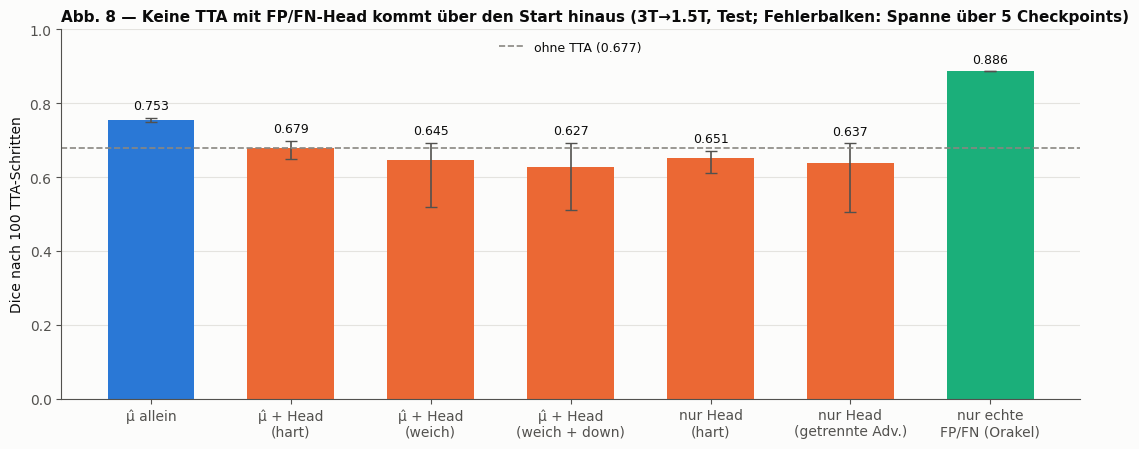

In [16]:
HEAD_RUNS = [('μ̂ allein', 'latent_tta_prenorm', C_MU),
             ('μ̂ + Head (hart)', 'latent_tta_mu_fpfnhead_w1.0', C_HEAD),
             ('μ̂ + Head (weich)', 'latent_tta_mu_fpfnheadsoft_w1.0', C_HEAD),
             ('μ̂ + Head (weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0', C_HEAD),
             ('nur Head (hart)', 'latent_tta_fpfnonly_head', C_HEAD),
             ('nur Head (getrennte Adv.)', 'latent_tta_fpfnonly_head_fpfnsplit', C_HEAD),
             ('nur echte FP/FN (Orakel)', 'latent_tta_fpfnonly_oracle', C_ORACLE)]
TICK8 = {'μ̂ allein': 'μ̂ allein', 'μ̂ + Head (hart)': 'μ̂ + Head\n(hart)', 'μ̂ + Head (weich)': 'μ̂ + Head\n(weich)',
         'μ̂ + Head (weich + down)': 'μ̂ + Head\n(weich + down)', 'nur Head (hart)': 'nur Head\n(hart)',
         'nur Head (getrennte Adv.)': 'nur Head\n(getrennte Adv.)', 'nur echte FP/FN (Orakel)': 'nur echte\nFP/FN (Orakel)'}
fig, ax = plt.subplots(figsize=(11, 4.6))
start = before_dice(T15)
x = np.arange(len(HEAD_RUNS))
means, lo, hi = [], [], []
for name, run, c in HEAD_RUNS:
    v = after_per_ckpt(run, T15)
    means.append(np.mean(v)); lo.append(np.mean(v) - min(v)); hi.append(max(v) - np.mean(v))
bars = ax.bar(x, means, 0.62, color=[c for _, _, c in HEAD_RUNS])
ax.errorbar(x, means, yerr=[lo, hi], fmt='none', ecolor=INK2, elinewidth=1.2, capsize=4)
for xi, m, h in zip(x, means, hi):
    ax.text(xi, m + h + 0.015, f'{m:.3f}', ha='center', va='bottom', fontsize=9)
ax.axhline(start, color=START, ls='--', lw=1.2, label=f'ohne TTA ({start:.3f})')
ax.legend(loc='upper center', fontsize=9)
ax.set_xticks(x, [TICK8[n] for n, _, _ in HEAD_RUNS]); ax.grid(axis='x', visible=False)
ax.set_ylim(0, 1.0); ax.set_ylabel('Dice nach 100 TTA-Schritten')
ax.set_title('Abb. 8 — Keine TTA mit FP/FN-Head kommt über den Start hinaus (3T→1.5T, Test; Fehlerbalken: Spanne über 5 Checkpoints)',
             loc='left')
fig.tight_layout()

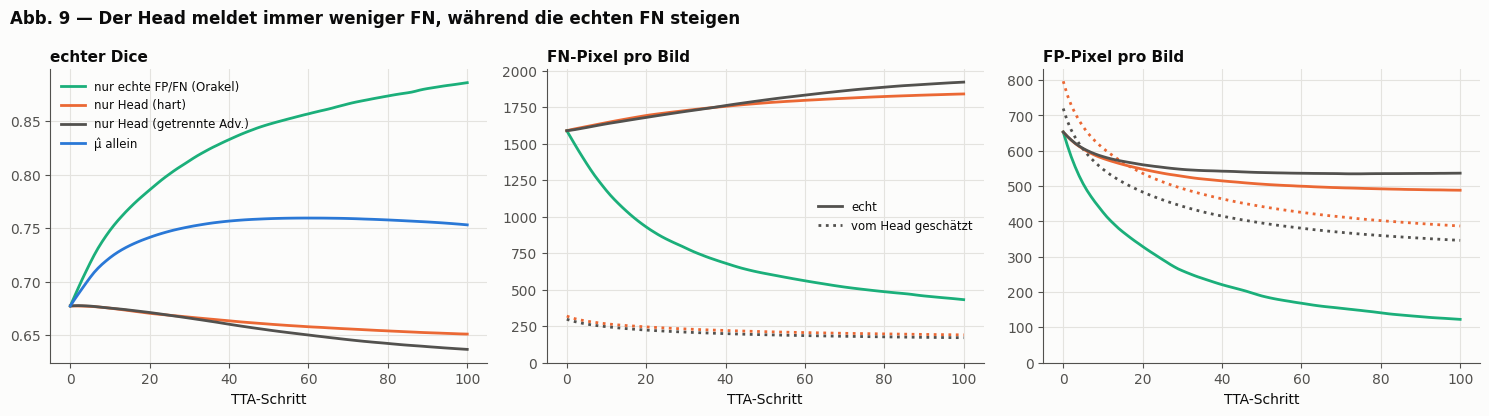

In [17]:
traj = {'nur echte FP/FN (Orakel)': (per_step_means('latent_tta_fpfnonly_oracle', T15), C_ORACLE),
        'nur Head (hart)': (per_step_means('latent_tta_fpfnonly_head', T15), C_HEAD),
        'nur Head (getrennte Adv.)': (per_step_means('latent_tta_fpfnonly_head_fpfnsplit', T15), REF),
        'μ̂ allein': (per_step_means('latent_tta_prenorm', T15), C_MU)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for name, (t, c) in traj.items():
    if 'dice_per_step' in t:
        ax.plot(t['dice_per_step'], color=c, label=name)
ax.set_title('echter Dice', loc='left'); ax.set_xlabel('TTA-Schritt'); ax.legend(fontsize=8.5)
for ax, key, name in ((axes[1], 'fn', 'FN'), (axes[2], 'fp', 'FP')):
    for run, (t, c) in traj.items():
        if f'{key}_hard_per_step' in t and run != 'μ̂ allein':
            ax.plot(t[f'{key}_hard_per_step'], color=c)
        if f'{key}_pred_per_step' in t:
            ax.plot(t[f'{key}_pred_per_step'], color=c, ls=':')
    ax.set_title(f'{name}-Pixel pro Bild', loc='left'); ax.set_xlabel('TTA-Schritt'); ax.set_ylim(bottom=0)
axes[1].legend(handles=[Line2D([], [], color=INK2, label='echt'), Line2D([], [], color=INK2, ls=':', label='vom Head geschätzt')],
               fontsize=8.5)
fig.suptitle('Abb. 9 — Der Head meldet immer weniger FN, während die echten FN steigen', x=0.01, ha='left')
fig.tight_layout()

Text(0.01, 0.98, 'Abb. 10 — Die zwei schwierigsten Beispiele (3T→1.5T, Checkpoint 0): μ̂ und Head lassen die falschen\nBereiche stehen, echte FP/FN räumen sie weg')

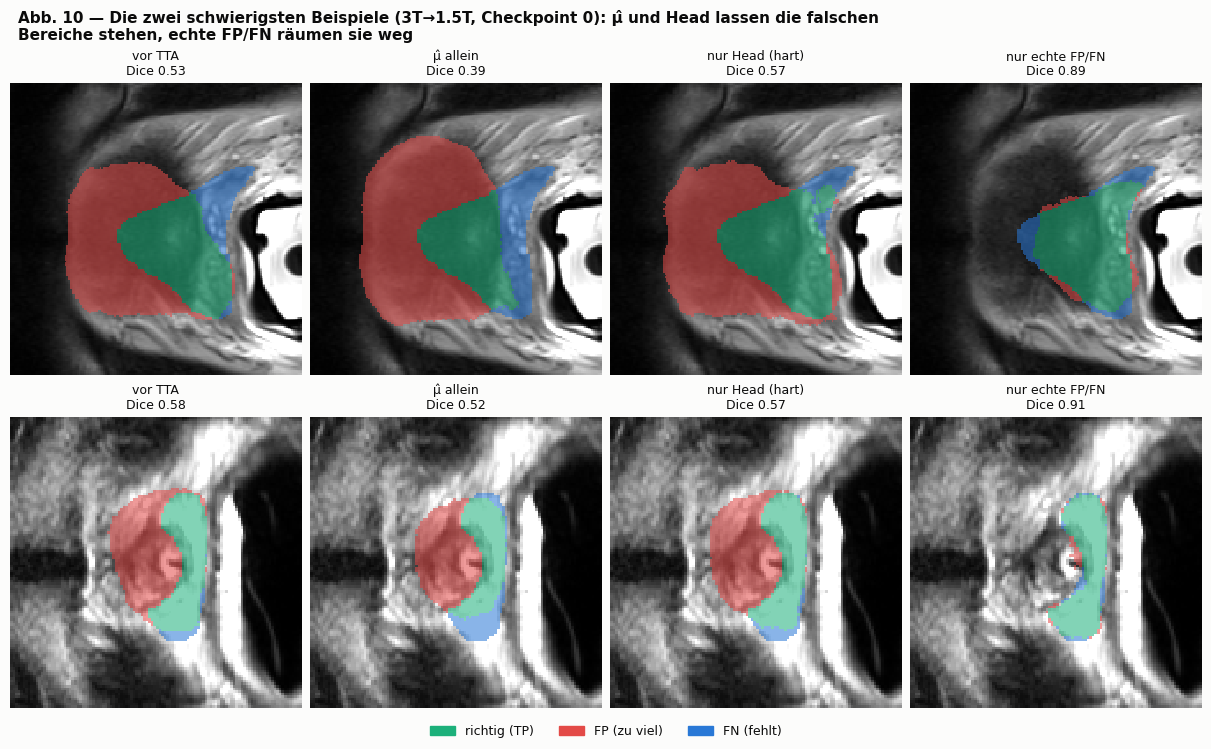

In [18]:
COLS4 = [('vor TTA', 'latent_tta_prenorm', 'pred_before'), ('μ̂ allein', 'latent_tta_prenorm', 'pred_final'),
         ('nur Head (hart)', 'latent_tta_fpfnonly_head', 'pred_final'),
         ('nur echte FP/FN', 'latent_tta_fpfnonly_oracle', 'pred_final')]
es = evals('latent_tta_prenorm', T15)[0]
idxs = es['examples']['index'].tolist()
gain = {i: float(es['dice_before'][i]) for i in idxs}
pick = sorted(idxs, key=lambda i: gain[i])[:2]   # die zwei schwierigsten gespeicherten Beispiele
fig, axes = plt.subplots(len(pick), len(COLS4), figsize=(3 * len(COLS4), 3.4 * len(pick) + 0.6), squeeze=False,
                         layout='constrained')
for row, idx in zip(axes, pick):
    exs = [(t, example(r, T15, idx, k)) for t, r, k in COLS4]
    ref = next(e for _, e in exs if e is not None)
    box = crop_box([ref['target']] + [e['pred'] for _, e in exs if e is not None])
    for ax, (t, e) in zip(row, exs):
        if e is None:
            ax.axis('off'); continue
        error_panel(ax, e['image'], e['pred'], e['target'], t, box)
fig.legend(handles=ERR_LEGEND, loc='outside lower center', ncol=3, fontsize=9)
fig.suptitle('Abb. 10 — Die zwei schwierigsten Beispiele (3T→1.5T, Checkpoint 0): μ̂ und Head lassen die falschen\n'
             'Bereiche stehen, echte FP/FN räumen sie weg', x=0.01, ha='left', fontsize=11)

Die Adaptation findet Richtungen, in denen der Head weniger Fehler *meldet*, ohne dass die Maske
besser wird. Das liegt am Mechanismus: Der Gradient läuft durch den Head (auch direkt über die
Features 0 / 17, die die TTA verändert) statt — wie beim Orakel — nur über die Maske. Die Zahl
des Heads mag am Start stimmen, ihre *Steigung* in die Richtungen, die die TTA ausprobiert, ist
nie trainiert worden. Mit μ̂ im Objective (exp7) wird das nur gedämpft.

## 5 · Getrennte FP- und FN-Adversaries im Head-Training

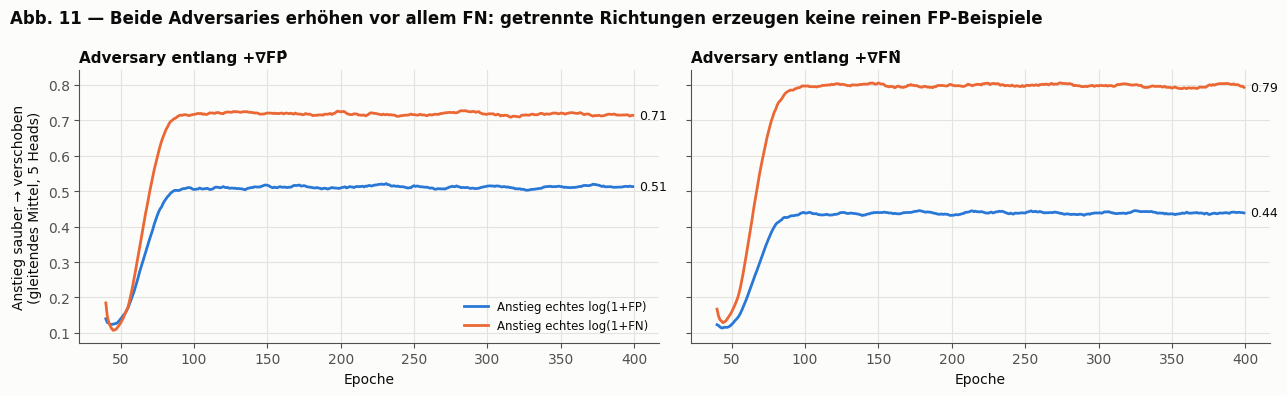

In [19]:
recs = []
for f in sorted(LOGS.glob('train_fpfnsplit_head_[0-9].log')):
    for line in open(f, errors='ignore'):
        for m in ADV_LINE.finditer(line):
            recs.append({'head': f.stem[-1], 'epoch': int(m.group(1)), 'adv': m.group(2),
                         'drop': float(m.group(4)), 'dFP': float(m.group(5)), 'dFN': float(m.group(6))})
adv = pd.DataFrame(recs)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, a, title in ((axes[0], 'FP', 'Adversary entlang +∇FP̂'), (axes[1], 'FN', 'Adversary entlang +∇FN̂')):
    d = adv[adv.adv == a].groupby('epoch')[['dFP', 'dFN']].mean().rolling(15, min_periods=1).mean()
    d = d[d.index >= 40]
    ax.plot(d.index, d['dFP'], color=BLUE, label='Anstieg echtes log(1+FP)')
    ax.plot(d.index, d['dFN'], color=ORANGE, label='Anstieg echtes log(1+FN)')
    for col, c in (('dFP', BLUE), ('dFN', ORANGE)):
        ax.text(d.index[-1] + 4, d[col].iloc[-1], f'{d[col].iloc[-1]:.2f}', va='center', fontsize=9, color=INK)
    ax.set_title(title, loc='left'); ax.set_xlabel('Epoche')
axes[0].set_ylabel('Anstieg sauber → verschoben\n(gleitendes Mittel, 5 Heads)'); axes[0].legend(fontsize=8.5)
fig.suptitle('Abb. 11 — Beide Adversaries erhöhen vor allem FN: getrennte Richtungen erzeugen keine reinen FP-Beispiele',
             x=0.01, ha='left')
fig.tight_layout()

Wer das Bild in Richtung „mehr FP laut Head“ verschiebt, erzeugt in der Praxis trotzdem vor allem
fehlende Pixel. FN-erhöhende Beispiele gab es im Training also reichlich; die FN-Unterschätzung unter
Shift (Abb. 7) ist ein Generalisierungsproblem des Heads, keine fehlende Trainingsrichtung.

## 6 · Pseudo-Label-Orakel: Wie gut muss eine Label-Karte ĝ sein? (exp9, 3T→1.5T)

Das Orakel-Objective, aber statt der Labels g eine feste, absichtlich verschlechterte Karte ĝ
(ohne Gradient): FP = Σ p(1−ĝ), FN = Σ (1−p)ĝ. Genau so würde ein Head mit Pixel-Karte eingesetzt.
Der Gradient läuft wie beim Orakel nur über die Maske.

- **recall r:** ĝ = Maske vor TTA, bei der ein Anteil r ihrer Fehlerpixel korrigiert ist (zusammenhängende
  Flecken von ~16 px). r = 1 ist das Orakel, r = 0 ist ĝ = Maske vor TTA (keine Information).
- **morph ±3:** ĝ = Label um 3 px vergrößert / verkleinert (systematisch falscher Rand).

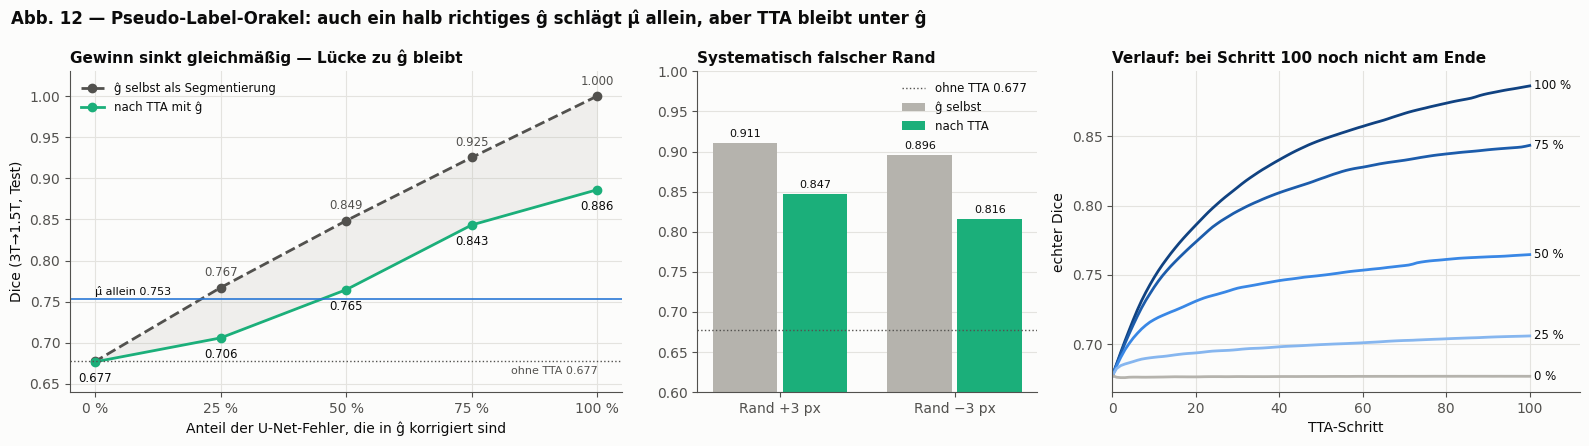

In [20]:
PSEUDO = [(1.0, 'latent_tta_pseudo_recall1.0'), (0.75, 'latent_tta_pseudo_recall0.75'), (0.5, 'latent_tta_pseudo_recall0.5'),
          (0.25, 'latent_tta_pseudo_recall0.25'), (0.0, 'latent_tta_pseudo_recall0.0')]
MORPH = [('Rand +3 px', 'latent_tta_pseudo_morph3'), ('Rand −3 px', 'latent_tta_pseudo_morph-3')]
def pseudo_stats(run):
    e = evals(run, T15)[0]
    return float(e['pseudo_dice'].mean()), float(e['dice_after'].float().mean()), float(e['dice_before'].float().mean())
P = [(r, *pseudo_stats(run)) for r, run in PSEUDO if tta_files(run, T15)]
M = [(n, *pseudo_stats(run)) for n, run in MORPH if tta_files(run, T15)]
start = P[0][3]
mu_only = np.mean(after_per_ckpt('latent_tta_prenorm', T15))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.3, 0.8, 1.1]})
ax = axes[0]
r, g, a = np.array([p[0] for p in P]), np.array([p[1] for p in P]), np.array([p[2] for p in P])
ax.fill_between(r, a, g, color=NEUTRAL, alpha=0.18, lw=0)
ax.plot(r, g, color=INK2, ls='--', marker='o', label='ĝ selbst als Segmentierung')
ax.plot(r, a, color=C_ORACLE, marker='o', label='nach TTA mit ĝ')
for ri, gi, ai in zip(r, g, a):
    ax.text(ri, ai - 0.012, f'{ai:.3f}', ha='center', va='top', fontsize=8.5, color=INK)
    if ri > 0:
        ax.text(ri, gi + 0.01, f'{gi:.3f}', ha='center', va='bottom', fontsize=8.5, color=INK2)
ax.axhline(start, color=INK2, lw=1, ls=':'); ax.text(1.0, start - 0.006, f'ohne TTA {start:.3f}', ha='right', va='top', fontsize=8, color=INK2)
ax.axhline(mu_only, color=C_MU, lw=1.2); ax.text(0.0, mu_only + 0.005, f'μ̂ allein {mu_only:.3f}', fontsize=8, color=INK)
ax.set_xlabel('Anteil der U-Net-Fehler, die in ĝ korrigiert sind'); ax.set_ylabel('Dice (3T→1.5T, Test)')
ax.set_xticks(r, [f'{int(100 * x)} %' for x in r]); ax.set_ylim(0.64, 1.03)
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Gewinn sinkt gleichmäßig — Lücke zu ĝ bleibt', loc='left')

ax = axes[1]
x = np.arange(len(M));
b1 = ax.bar(x - 0.2, [m[1] for m in M], 0.37, color=NEUTRAL, label='ĝ selbst')
b2 = ax.bar(x + 0.2, [m[2] for m in M], 0.37, color=C_ORACLE, label='nach TTA')
label_bars(ax, list(b1) + list(b2), fmt='{:.3f}', pad=0.005, horizontal=False)
ax.axhline(start, color=INK2, lw=1, ls=':', label=f'ohne TTA {start:.3f}')
ax.set_xticks(x, [m[0] for m in M]); ax.set_ylim(0.6, 1.0); ax.grid(axis='x', visible=False)
ax.legend(fontsize=8.5, loc='upper right'); ax.set_title('Systematisch falscher Rand', loc='left')

ax = axes[2]
for (rr, run), c in zip(PSEUDO, SEQ + [NEUTRAL]):
    t = per_step_means(run, T15)
    ax.plot(t['dice_per_step'], color=c, label=f'{int(100 * rr)} %')
    ax.text(101, t['dice_per_step'][-1], f'{int(100 * rr)} %', va='center', fontsize=8.5)
ax.set_xlabel('TTA-Schritt'); ax.set_ylabel('echter Dice'); ax.set_xlim(0, 112)
ax.set_title('Verlauf: bei Schritt 100 noch nicht am Ende', loc='left')
fig.suptitle('Abb. 12 — Pseudo-Label-Orakel: auch ein halb richtiges ĝ schlägt μ̂ allein, aber TTA bleibt unter ĝ',
             x=0.01, ha='left')
fig.tight_layout()

Text(0.01, 0.98, 'Abb. 13 — Pseudo-Label-Karten ĝ (Anteil korrigierter Fehler) und das Ergebnis der TTA damit (Farben: Fehler gegenüber dem echten Label)')

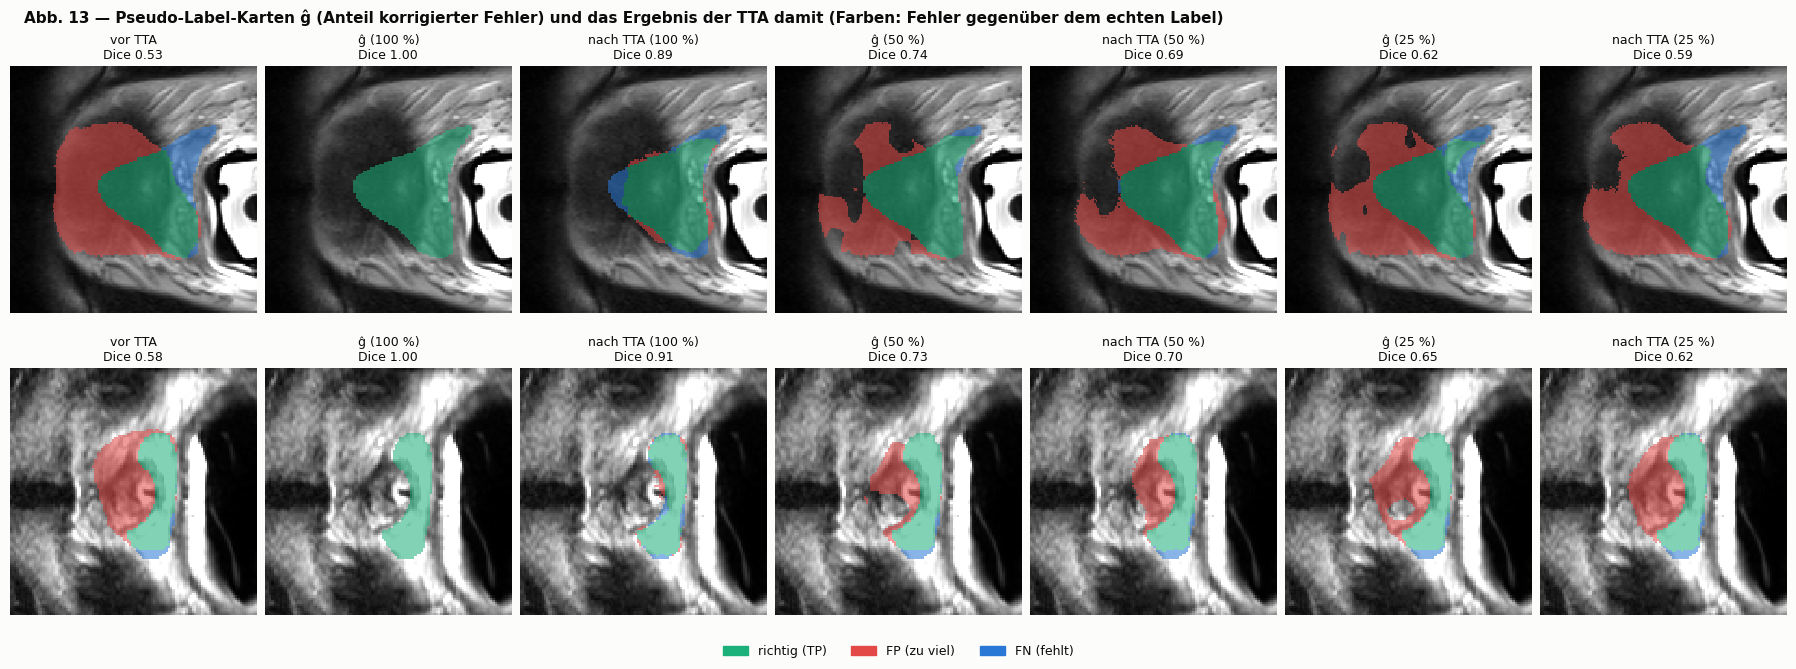

In [21]:
LV = [(1.0, 'latent_tta_pseudo_recall1.0'), (0.5, 'latent_tta_pseudo_recall0.5'), (0.25, 'latent_tta_pseudo_recall0.25')]
e0 = evals('latent_tta_pseudo_recall1.0', T15)[0]
idxs = e0['examples']['index'].tolist()
pick = sorted(idxs, key=lambda i: float(e0['dice_before'][i]))[:2]
fig, axes = plt.subplots(len(pick), 1 + 2 * len(LV), figsize=(2.55 * (1 + 2 * len(LV)), 3.0 * len(pick) + 0.6),
                         squeeze=False, layout='constrained')
for row, idx in zip(axes, pick):
    base = example(LV[0][1], T15, idx, 'pred_before')
    panels = [('vor TTA', base['pred'])]
    for rr, run in LV:
        panels.append((f'ĝ ({int(100 * rr)} %)', example(run, T15, idx, 'pseudo_target')['pred']))
        panels.append((f'nach TTA ({int(100 * rr)} %)', example(run, T15, idx)['pred']))
    box = crop_box([base['target']] + [p for _, p in panels])
    for ax, (t, p) in zip(row, panels):
        error_panel(ax, base['image'], p, base['target'], t, box)
fig.legend(handles=ERR_LEGEND, loc='outside lower center', ncol=3, fontsize=9)
fig.suptitle('Abb. 13 — Pseudo-Label-Karten ĝ (Anteil korrigierter Fehler) und das Ergebnis der TTA damit '
             '(Farben: Fehler gegenüber dem echten Label)', x=0.01, ha='left', fontsize=11)

- **Der Mechanismus trägt:** Der Gewinn fällt gleichmäßig mit der Qualität von ĝ, ohne Absturz. Sind
  nur die Hälfte der Fehler in ĝ korrigiert, ist die TTA immer noch besser als μ̂ allein. Ein um 3 px
  falscher Rand kostet wenig; zu groß ist besser als zu klein, weil auf diesem Split FN dominieren.
  r = 100 % reproduziert das Orakel aus exp8 exakt (Plausibilitätsprüfung).
- **Aber:** In jeder Variante landet die TTA *unter* ĝ selbst (graue Fläche) und setzt nur einen Teil
  der Verbesserung um, die schon in ĝ steckt. Ein Head, der ein vollständiges ĝ liefert, wäre direkt
  als Segmentierung besser. TTA lohnt sich damit nur, wenn sie etwas kann, das ĝ nicht kann — etwa
  Korrekturen aus einem *teilweisen* ĝ (nur sichere Pixel) auf den Rest übertragen. Noch nicht getestet.
- Verpasste Prostatas bleiben auch mit ĝ = Label die Schwachstelle; pro Rauschstufe gibt es bisher nur
  einen Seed.

## Offene Punkte / nächste Schritte

1. **Dichter Fehlerkarten-Head (vorgemerkt).** Pro Pixel richtig / FP / FN aus denselben drei Schichten
   der eingefrorenen U-Net, 5 Seeds. Entscheidend sind die Trainingsdaten: nicht nur die
   U-Net-Trainingsbilder (Abschnitt 3), sondern erzeugte Fehler (Shift-Augmentierungen, Input-Adversary,
   Cross-Fitting). Auswertung: (1) Qualität von ĝ auf der Zieldomäne → Einordnung in Abb. 12,
   (2) ĝ direkt als Segmentierung, (3) TTA mit ĝ als Pseudo-Label (schon eingebaut, `fpfn_source=pseudo`).
2. **Teil-ĝ-Test:** Pseudo-Label nur auf einem Teil der Pixel; überträgt die TTA Korrekturen auf den
   Rest? Nur dann hat TTA einen Mehrwert gegenüber ĝ direkt. Dazu mehrere Seeds pro Stufe.
3. **Modellauswahl und Lernrate:** Für neue Heads den LR-Scheduler auf `val_loss_clean` (oder einen
   Loss, dessen Definition sich nicht ändert) hängen bzw. erst nach dem Warm-up starten; Checkpoints nach
   Validierung über Epochenfenster auswählen. Bei den bisherigen Heads hätte eine andere
   Checkpoint-Wahl nichts geändert (Abb. 7b, 7c), aber sie wurden durch den Scheduler früh eingefroren
   (Abb. 7e).
4. **Größerer Dice-Abfall / zählbasierte Controller** im Head-Training: verbreitert den Fehlerbereich,
   löst aber weder Abschnitt 3 noch Abschnitt 5 — niedrige Priorität.
5. **Verpasste Prostatas** (Abschnitt 2) sind für ein FP/FN-Objective mit lokalem Optimierer außer
   Reichweite; sie bräuchten eine Erkennung auf Bildebene (z. B. Markieren über μ̂) statt Adaptation.

## Anhang · Tabellen

In [22]:
ALL = [('μ̂ allein', 'latent_tta_prenorm'), ('Dice-Orakel', 'latent_tta_oracle'),
       ('Größen-Orakel w0.1', 'latent_tta_mu_size_w0.1'), ('Größen-Orakel w1.0', 'latent_tta_mu_size_w1.0'),
       ('Größen-Orakel ±10 %', 'latent_tta_mu_size_w1.0_noise0.1'), ('Größen-Orakel ±20 %', 'latent_tta_mu_size_w1.0_noise0.2'),
       ('Größen-Orakel ±30 %', 'latent_tta_mu_size_w1.0_noise0.3'),
       ('μ̂ + FP/FN getrennt w0.1', 'latent_tta_mu_fpfn_w0.1'), ('μ̂ + FP/FN getrennt w1.0', 'latent_tta_mu_fpfn_w1.0'),
       ('μ̂ + FP/FN gemeinsam w0.1', 'latent_tta_mu_fpfn_joint_w0.1'), ('μ̂ + FP/FN gemeinsam w1.0', 'latent_tta_mu_fpfn_joint_w1.0'),
       ('μ̂ + FP/FN gemeinsam, FN×3', 'latent_tta_mu_fpfn_joint_fn3.0_w1.0'),
       ('nur echte FP/FN', 'latent_tta_fpfnonly_oracle'),
       ('μ̂ + Head (hart)', 'latent_tta_mu_fpfnhead_w1.0'), ('μ̂ + Head (weich)', 'latent_tta_mu_fpfnheadsoft_w1.0'),
       ('μ̂ + Head (weich + down)', 'latent_tta_mu_fpfnheadsoftdown_w1.0'),
       ('nur Head (hart)', 'latent_tta_fpfnonly_head'), ('nur Head (getrennte Adv.)', 'latent_tta_fpfnonly_head_fpfnsplit')] + \
      [(f'Pseudo-Label {int(100 * r)} %', run) for r, run in PSEUDO] + [(f'Pseudo-Label {n}', run) for n, run in MORPH]
cols = ['before', 'after', 'after ± (ckpts)', 'best step', 'worse %', 'empty %', 'FP before', 'FP after', 'FN before', 'FN after',
        'FP_hat before', 'FP_hat after', 'FN_hat before', 'FN_hat after', 'n ckpts']
tab = tta_table(ALL, cols=cols)
tab.columns = ['vorher', 'nachher', '± Checkpoints', 'bester Schritt', 'schlechter %', 'leer %', 'FP vorher', 'FP nachher',
               'FN vorher', 'FN nachher', 'FP̂ vorher', 'FP̂ nachher', 'FN̂ vorher', 'FN̂ nachher', 'Checkpoints']
fmt = {c: '{:.3f}' for c in tab.columns}
fmt.update({c: '{:.0f}' for c in tab.columns if c.startswith(('FP', 'FN')) or c == 'Checkpoints'})
fmt.update({c: '{:.1f}' for c in tab.columns if '%' in c})
tab.style.format(fmt, na_rep='–')

,,vorher,nachher,± Checkpoints,bester Schritt,schlechter %,leer %,FP vorher,FP nachher,FN vorher,FN nachher,FP̂ vorher,FP̂ nachher,FN̂ vorher,FN̂ nachher,Checkpoints
split,run,,,,,,,,,,,,,,,
3T→1.5T,μ̂ allein,0.677,0.753,0.004,0.783,25.8,–,–,–,–,–,–,–,–,–,5
PROMISE12,μ̂ allein,0.642,0.702,0.011,0.717,19.2,–,–,–,–,–,–,–,–,–,5
1.5T→3T,μ̂ allein,0.526,0.538,0.001,0.546,14.5,–,–,–,–,–,–,–,–,–,5
3T→1.5T,Dice-Orakel,0.677,0.937,0.000,0.938,0.0,–,–,–,–,–,–,–,–,–,5
PROMISE12,Dice-Orakel,0.642,0.926,0.000,0.926,0.0,–,–,–,–,–,–,–,–,–,5
1.5T→3T,Dice-Orakel,0.526,0.874,0.000,0.874,0.0,–,–,–,–,–,–,–,–,–,5
3T→1.5T,Größen-Orakel w0.1,0.677,0.792,0.005,0.804,7.8,0.0,653,874,1590,708,–,–,–,–,5
PROMISE12,Größen-Orakel w0.1,0.642,0.734,0.014,0.742,8.3,0.0,1013,1187,1995,1204,–,–,–,–,5
1.5T→3T,Größen-Orakel w0.1,0.526,0.564,0.001,0.570,7.5,0.0,1621,1604,2069,1917,–,–,–,–,5


In [23]:
heads_all = head_table(HEADS + [('FP-Head (getrennt)', T15, 'fpfnsepfp'), ('FN-Head (getrennt)', T15, 'fpfnsepfn'),
                                ('hart', 'promise12', 'fpfn'), ('hart', 'onepointfivet-to-threet', 'fpfn')])
heads_all.style.format('{:.3f}', na_rep='–')